# Referral Saathi: whom to call first, and why

A health worker in rural India has a patient who needs dialysis, an emergency caesarean or trauma care. The
facility list she could search says many things that are not true: hospitals that "offer" a service because a
sentence about another hospital was pasted into their record, map points in the wrong district, and claims no one
has checked. **Referral Saathi** reads every listing sentence, keeps only evidence about the facility itself,
says how sure it is in words, and tells her whom to call first and why. It works offline and on a cheap phone.

This notebook is the code and the reasoning behind the app, in plain words first:

1. The problem and the data
2. What is wrong with the data
3. Cleaning: fixed, flagged, and what cannot be fixed
4. Sources and external evidence
   - 4b. What each outside source adds
5. The knowledge base
6. The model and an honest evaluation
7. `recommend(service, location)` with its WHY and HOW, on 3 real queries, including a multi-stop plan
   - 7b. What we compared against: not the nearest, not the unreachable best
8. Data stories
9. Limits
10. How to open the app

Every number below is computed in this notebook from the repository's files or the provided dataset, or copied
from a named report file by a function that fails if the report changes shape. Outputs show aggregate numbers,
charts and a few quoted facility sentences as examples. No table of the provided records is printed.

## 0. Setup

**To rebuild the team dataset on Databricks first:** run `submission/00_rebuild_derived.ipynb`. It reads the
Marketplace tables on Free Edition serverless, runs the repository's rules-only cleaning, claims and source-scoring
pipeline, writes `derived/v1` to a Unity Catalog volume and checks every table against `derived/v1/MANIFEST.json`.
The cell below prints the result of its last Free Edition run. This notebook then reads `derived/v1` and the frozen
model v2 export in `derived/v2`.

**On Databricks Free Edition:** clone the repository as a Git folder and open this notebook from `submission/`.
It reads the provided dataset from the Marketplace catalog through Spark. If you installed the listing under
another catalog name, change `CATALOG` below.

**Locally:** the same cells read the repository's cleaned tables in `derived/v1/` instead. Set `MODE` below to
force one or the other.

**Your own rebuild:** `00_rebuild_derived.ipynb` rebuilds `derived/v1` from the Marketplace table into a volume.
Put that folder (the one holding `derived/v1`, by default `/Volumes/workspace/referral_saathi/uploads/rebuild`) in
the `data_root` widget, or in the `DATATHON_ROOT` environment variable locally. Every table below and the app
builds then read your rebuild, and section 0.1 checks that it gives the same app as the repository's copy. Empty
means the repository's `derived/v1`.

Some steps cannot run inside Free Edition: the website crawl, web labelling and external downloads. They ran
offline. Their outputs are summary files in the repository, or tables in a Unity Catalog volume (`VOLUME`).
Each section that uses one says so.

In [1]:
import hashlib
import json
import math
import os
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

MODE = "auto"   # "auto", "databricks" or "local"
CATALOG = "databricks_virtue_foundation_dataset_dais_2026"
SCHEMA = "virtue_foundation_dataset"
VOLUME = f"/Volumes/{CATALOG}/referral_saathi/offline_outputs"   # created by the team for the offline steps

ON_DATABRICKS = MODE == "databricks" or (MODE == "auto" and "DATABRICKS_RUNTIME_VERSION" in os.environ)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "derived" / "v1").is_dir())
for p in (ROOT, ROOT / "app"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 3.2), "axes.spines.top": False,
                     "axes.spines.right": False})
# Where derived/v1 is read from: the data_root widget on Databricks, else DATATHON_ROOT, else this repository.
try:
    dbutils.widgets.text("data_root", "")  # noqa: F821 (dbutils is predefined on Databricks)
    DATA_ROOT = Path(dbutils.widgets.get("data_root") or os.environ.get("DATATHON_ROOT") or ROOT)  # noqa: F821
except NameError:
    DATA_ROOT = Path(os.environ.get("DATATHON_ROOT") or ROOT)
if not (DATA_ROOT / "derived" / "v1" / "MANIFEST.json").is_file():
    raise FileNotFoundError(f"{DATA_ROOT}/derived/v1/MANIFEST.json not found: check data_root")
os.environ["DATATHON_ROOT"] = str(DATA_ROOT)  # the app builds below (subprocesses) read the same folder
V1 = DATA_ROOT / "derived" / "v1"
REPO_URL = "https://github.com/LordKarV/databricksdatathon/blob/main/"
print("running on", "Databricks" if ON_DATABRICKS else "a local machine", "| repository at", ROOT.name,
      "| derived/v1 from", "the repository" if DATA_ROOT == ROOT else DATA_ROOT)
rebuilt = re.search(r"On Free Edition serverless it gave [^.]+\.", (ROOT / "submission/README.md").read_text())
print("00_rebuild_derived.ipynb:", " ".join(rebuilt.group(0).split()) if rebuilt else "no Free Edition run recorded")

running on a local machine | repository at ws5-e | derived/v1 from the repository
00_rebuild_derived.ipynb: On Free Edition serverless it gave 20 of 20 tables passing (17 equal to the manifest, 3 CSV copies by rows).


The app reads small exports built from `derived/v1` and `derived/v2`, using only the standard library at run time.
The next cell rebuilds them every time (a few seconds each), so an export left over from an older checkout can never
be read by mistake; a failed build stops the notebook. The order matters: the planner first, then the facts, whose
export copies the sentences the planner cites, then the "How this works" page data.

In [2]:
BUILDS = [("planner/out/planner_v2.json.gz", "planner/export_v2.py"),
          ("app/facts/out/facts.json.gz", "app/facts/build.py"),
          ("app/howto/out/how.json", "app/howto/build.py")]
for out, script in BUILDS:  # always rebuild: a stale export once broke a Databricks run
    r = subprocess.run([sys.executable, script], cwd=ROOT, capture_output=True, text=True, check=False)
    if r.returncode != 0:
        raise RuntimeError(f"{script} failed: {r.stderr[-800:]}")
    print(f"built   {out}: {r.stdout.strip().splitlines()[-1] if r.stdout.strip() else 'ok'}")

built   planner/out/planner_v2.json.gz:   nicu                         677 facilities  derived/v2 nicu


built   app/facts/out/facts.json.gz: 9947 facilities, 7618 pairs, 42801 claims, 19484 PINs, 146162 places (places.json.gz); 12.4 MB raw, 2.4 MB gz; 3.7 s; sha 2bae5b4512c0


built   app/howto/out/how.json: how.json: 57 facts, 10 tables, 27.8 KB; drift check: 15 REPORT.md numbers match derived/v1


### 0.1 Check: does your rebuild give the same app?

Runs only when `data_root` points at a rebuild. It builds the app's facility facts and the 36 offline state packs
twice, from the repository's `derived/v1` and from yours, into a temporary folder, and compares them. The facts
hash covers every facility, pair, quote and score the app serves, but not the build time or the folder it was
read from. The packs are compared byte for byte with the same build date. PASS means a judge's rebuild drives
exactly the app we ship. Table-level checks against `MANIFEST.json` are in `00_rebuild_derived.ipynb`.

In [3]:
import tempfile


def app_build(data_root: Path, out: Path, built: str) -> dict:
    """Facts hash and per-state pack hashes, built from data_root/derived/v1 into out."""
    env = {**os.environ, "DATATHON_ROOT": str(data_root)}
    for script, args in (("app/facts/build.py", ["--out", str(out / "facts")]),
                         ("app/packs/build_packs.py", ["--out", str(out / "packs"), "--built", built])):
        r = subprocess.run([sys.executable, script, *args], cwd=ROOT, env=env, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"{script} failed on {data_root}: {r.stderr[-500:] or r.stdout[-500:]}")
    packs = json.loads((out / "packs" / "index.json").read_text())["packs"]
    return {"facts": (out / "facts" / "facts.sha").read_text().strip(),
            "packs": {k: v["sha256"] for k, v in packs.items()}}


if DATA_ROOT == ROOT:
    print("data_root is the repository: nothing to compare. Set data_root to your rebuild to run this check.")
else:
    built = json.loads((ROOT / "derived/v1/MANIFEST.json").read_text())["build_date"]
    with tempfile.TemporaryDirectory() as tmp:
        repo, mine = app_build(ROOT, Path(tmp) / "repo", built), app_build(DATA_ROOT, Path(tmp) / "mine", built)
    rows = [("facts (facilities, pairs, quotes, scores)", repo["facts"], mine["facts"])]
    rows += [(f"pack {k}", repo["packs"][k], mine["packs"].get(k, "missing")) for k in sorted(repo["packs"])]
    check = pd.DataFrame(rows, columns=["output", "from the repository", "from your rebuild"])
    check["result"] = (check["from the repository"] == check["from your rebuild"]).map({True: "PASS", False: "DIFF"})
    n_pass = int((check.result == "PASS").sum())
    print(f"{n_pass} of {len(check)} app outputs identical: {'PASS' if n_pass == len(check) else 'DIFF'}")
    display(check[check.result != "PASS"] if n_pass < len(check) else check.head(3))  # noqa: F821

data_root is the repository: nothing to compare. Set data_root to your rebuild to run this check.


## 1. The problem and the data

The provided dataset is one table of Indian health facilities, scraped from the web: names, addresses, map
points, phone numbers, and free-text lists of procedures, equipment, capabilities and specialties. A health
worker needs three facts from it, and it states none of them reliably:
- Does the facility exist?
- Is it where the map says?
- Does it really offer the service?

Local run: 9,959 usable records in derived/v1 (the cleaned copy of the provided table)


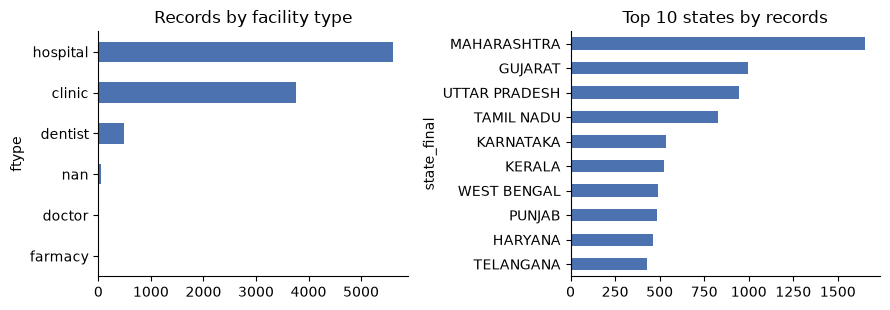

In [4]:
if ON_DATABRICKS:
    raw = spark.table(f"{CATALOG}.{SCHEMA}.facilities")  # noqa: F821 (spark is predefined on Databricks)
    n_records, n_columns = raw.count(), len(raw.columns)
    by_type = raw.groupBy("facilityTypeId").count().toPandas().set_index("facilityTypeId")["count"]
    by_state = (raw.groupBy("address_stateOrRegion").count().toPandas()
                .set_index("address_stateOrRegion")["count"])
    print(f"Provided table {CATALOG}.{SCHEMA}.facilities: {n_records:,} records, {n_columns} columns")
else:
    loc = pd.read_parquet(V1 / "facility_location.parquet", columns=["unique_id", "state_final"])
    # record counts by type for every usable record, as counted by the crawl's target builder
    by_type = pd.read_csv(ROOT / "kb/crawl/coverage_by_type.csv").set_index("ftype")["records"]
    n_records = len(loc)
    by_state = loc.state_final.value_counts()
    print(f"Local run: {n_records:,} usable records in derived/v1 (the cleaned copy of the provided table)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
by_type.sort_values().tail(6).plot.barh(ax=ax[0], color="#4c72b0", title="Records by facility type")
by_state.sort_values().tail(10).plot.barh(ax=ax[1], color="#4c72b0", title="Top 10 states by records")
plt.tight_layout()
plt.show()

## 2. What is wrong with the data

We audited the table before cleaning it. These are the five findings that matter most for a patient. Each count
was checked by hand on samples; the full method is in `REPORT.md`. The table is copied from the report by
`app/howto/build.py`, the same function that feeds the app's "How this works" page, so the notebook and the app
cannot disagree.

In [5]:
from howto import build as how


PHONE = r"(?:\+91[ -]?|\b)[6-9]\d{4}[ -]?\d{5}\b"  # Indian mobile numbers: never printed in this public notebook


def show_table(t, cols=None, max_chars=140):
    df = pd.DataFrame(t["rows"], columns=t["columns"]).replace(PHONE, "[a phone number]", regex=True)
    if cols:
        df = df[cols]
    with pd.option_context("display.max_colwidth", max_chars):
        display(df)
    print(f"source: {t['source']}, section '{t['heading']}'")

findings = how.table("REPORT.md", "1.1 The 5 findings", ["Finding", "Verified count / denominator",
                                                      "What goes wrong for a patient"])
show_table(findings)

,Finding,Verified count / denominator,What goes wrong for a patient
0,Records hold text about another facility (merged records),"2,489 / 9,959 records have a sentence that names another facility (25.0%); in 1,232 of them it is written as if about the record itself ...","Sent to an eye hospital for dialysis because a Delhi government hospital's sentence sits in its record (Aravind), or to Nagpur for servi..."
1,"Listing coordinates are often in the wrong town, usually in the right state","1,367 / 9,869 more than 50 km from their own PIN (1,101 more than 100 km); 1,297 of the 1,367 stay in the same state (nearest PIN centre...","Told a hospital is 5 km away when it is 300 km away (HOSMAT Bangalore is placed at Gadag, about 350 km off), or never shown the nearest ..."
2,"""Strong-looking"" evidence is often only wording or a label",Strong dialysis grades whose prerequisite is met by the claim sentence itself: 345 / 355. Trauma sentences with explicit trauma wording:...,"A one-word list item or a specialty tag ranks like a staffed unit; a highway trauma case goes to a nursing home with ""24/7 emergency care"""
3,"The ""official"" phone often reaches a directory or call centre","[a phone number] sits on 431 records in 37 state strings and is the officialPhone of 87. 348 / 9,464 officialPhones are held by records ...","The health worker calls to confirm a bed and reaches a real-estate or booking line, in an emergency"
4,Typed locations are ambiguous or silently wrong,"5 / 40 realistic inputs are district names in two states (Aurangabad, Bilaspur, Hamirpur, Pratapgarh, Balrampur); ""Hydrabad"" silently re...","A worker in Bihar typing ""Aurangabad"" gets Maharashtra hospitals about 1,000 km away"


source: REPORT.md, section '1.1 The 5 findings'


One of those findings, recomputed here from the cleaned location table: how far each record's map point is from the centre of its own PIN code.

1,367 of 9,869 map points are more than 50 km from their own PIN code (1,101 more than 100 km).


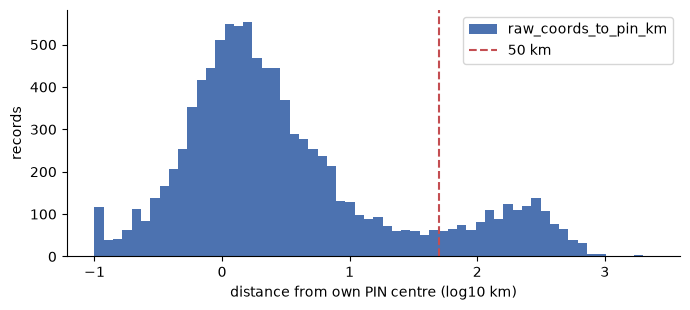

In [6]:
d = pd.read_parquet(V1 / "facility_location.parquet", columns=["raw_coords_to_pin_km"]).raw_coords_to_pin_km.dropna()
far50, far100 = int((d > 50).sum()), int((d > 100).sum())
print(f"{far50:,} of {len(d):,} map points are more than 50 km from their own PIN code ({far100:,} more than 100 km).")
ax = d.clip(lower=0.1).map(math.log10).plot.hist(bins=60, color="#4c72b0")
ax.axvline(math.log10(50), color="#c44e52", ls="--", label="50 km")
ax.set_xlabel("distance from own PIN centre (log10 km)")
ax.set_ylabel("records")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Cleaning: fixed, flagged, and what cannot be fixed

Cleaning does three different things, and the app treats them differently:
- **Fixed:** repaired in `derived/v1`.
- **Flagged:** kept, but shown to the user as a warning on the card.
- **Cannot be fixed by cleaning:** the answer is a phone call before travelling, and the app says so.

The fixed list below is the base everything else stands on: exact and residual duplicates, map points that were
impossible or outside India, and points moved to where the facility really is. What is left is mostly claims that
nobody can verify from the web, and the phone and opening-hours facts that no listing carries. That is why the
app says "call first", and section 6 measures how much of it remains.

In [7]:
fixed, flagged, cannot = (how.table("REPORT.md", h) for h in ("Fixed", "Flagged", "Cannot be handled by cleaning"))
print(f"fixed: {len(fixed['rows'])} problems | flagged: {len(flagged['rows'])} | cannot be fixed by cleaning: "
      f"{len(cannot['rows'])}")
show_table(cannot)
test_eval = ROOT / "model/gold/v3/test_eval/results.json"
if test_eval.is_file():
    v = json.loads(test_eval.read_text())["verdicts"]
    print(f"What remains after cleaning: in the held-out TEST set (opened once, after the model was frozen; "
          f"model/gold/v3/OPENING_LOG.md) a web check found no decisive answer for {v['no_info']} of "
          f"{sum(v.values())} facility-service pairs ({v['no_info'] / sum(v.values()):.0%}).")

fixed: 20 problems | flagged: 15 | cannot be fixed by cleaning: 5


,Issue,Size,Mitigation
0,Anonymous copied text (names no facility),"7,514 service sentences in 1,390 records; 1,161 of 4,151 v2 strong grades sit in such records; 0 of 20 hand-read sentences looked foreign","Record-level warning, ""call first"" default, field-call ledger. Optional offline ai_query attribution that can only lower a grade (specif..."
1,Merged multi-place records,"About 1,370 to 1,400 records","Not split; flags, second point, ""phone before travelling"""
2,Arrays truncated at 50 items,"1,495 records, 4,498 pairs","""A missing service may still exist"""
3,Merges where every field follows the other facility,Not countable,None in the data; only a phone call
4,Thin rural coverage,"Bihar: 260 of 9,959 records, 146 in Patna district",Coverage note on every result


source: REPORT.md, section 'Cannot be handled by cleaning'
What remains after cleaning: in the held-out TEST set (opened once, after the model was frozen; model/gold/v3/OPENING_LOG.md) a web check found no decisive answer for 90 of 150 facility-service pairs (60%).


In [8]:
show_table(fixed, max_chars=90)

,Issue,Before,After,Residual risk
0,Exact duplicate rows,"9,970 rows","9,959 records",None
1,Busy PINs far from facility consensus,"78 of 1,051 more than 25 km off (422009 Nashik 167.5 km)","43 of 1,051 (422009 now 2.5 km); 69 PINs overridden",Uses facility points to fix PIN points (circular in principle)
2,PINs misplaced inside small districts (403513 Pernem at sea),31 PINs wrong,31 moved to district median (radius 25 km),"Untuned 60 km, 3x rule"
3,Facility PINs missing from directory,134 PINs with no point,"127 have a point (14 consensus, 113 prefix median at 50 km radius)",Prefix point is district-level only
4,Coordinates outside India,6 used for distance,0 used; 9 marked city-level,Small
5,10 to 50 km band (mostly centroid imprecision),"1,081 records",718 records,"Some real errors labelled ""approximate"""
6,Stated state unusable for a filter,82 unresolved,32 unresolved; 0 records without a filter state,Pre-2014 Andhra labels stay flagged
7,District and NFHS join,"9,961 / 9,970 with 2 wrong joins","9,946 districts; 9,934 NFHS joins; 12 empty by design",Parent-district figures for split districts
8,Typed location input,38 of 40 audit tests; Hydrabad silent; homonyms auto-picked,54 of 54 on an extended self-written suite,"Regression suite, not an accuracy estimate"
9,Residual duplicates,0 linked,75 groups (152 records) shown as one card; 52 soft links; 17 co-located units,"In-sample: hard merge precision 0.84, recall 0.90 on the labels it was shaped on"


source: REPORT.md, section 'Fixed'


The core of the cleaning is sentence attribution. Every listing sentence is split out with an id, then tagged:
- about this facility (`own_anchored`);
- about another facility (`other_facility`, often copied from a group or a directory page);
- ambiguous;
- or unanchored (a plain service phrase with no name in it).

Only sentences about the facility itself, or unanchored sentences, count as evidence. The others are listed as
ignored.

469,498 listing sentences; 9,506 name another facility and never count as evidence for this one.


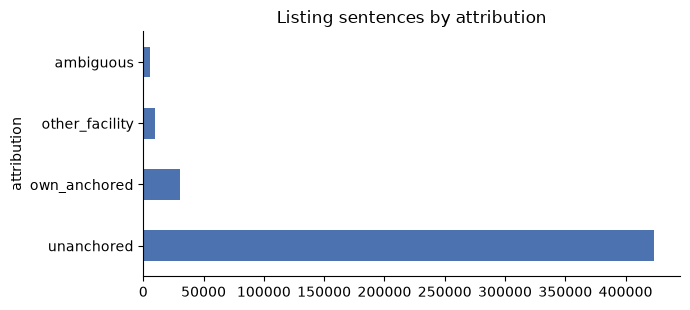

In [9]:
claims = pd.read_parquet(V1 / "claims.parquet", columns=["attribution"])
att = claims.attribution.value_counts()
print(f"{len(claims):,} listing sentences; {att.get('other_facility', 0):,} name another facility and never count "
      "as evidence for this one.")
att.plot.barh(color="#4c72b0", title="Listing sentences by attribution")
plt.tight_layout()
plt.show()

## 4. Sources and external evidence

Every record was scraped from web pages: social media pages, insurance-scheme lists, directories, the facility's
own website. We scored how often each kind of source was right, against claims confirmed or contradicted by a
second source. The reliability and its 90% interval come from `derived/v1/source_classes.csv`.

158,444 source URLs in 16 classes


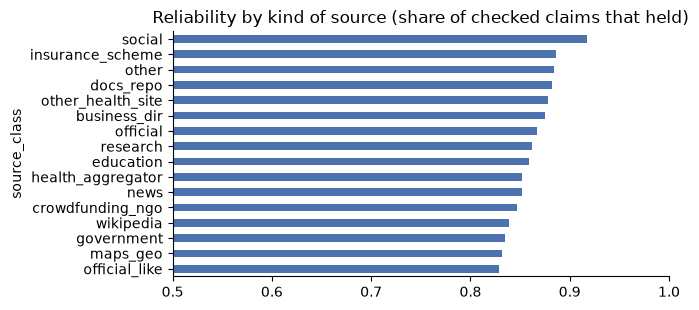

In [10]:
sc = pd.read_csv(V1 / "source_classes.csv").sort_values("n_urls", ascending=False)
print(f"{sc.n_urls.sum():,} source URLs in {len(sc)} classes")
ax = sc.set_index("source_class").reliability.sort_values().plot.barh(
    xerr=None, color="#4c72b0", title="Reliability by kind of source (share of checked claims that held)")
ax.set_xlim(0.5, 1)
plt.tight_layout()
plt.show()

Two offline witnesses add independent text and tags. Neither can run inside Free Edition: the crawl needs
outbound HTTP for about an hour, and the matching needs large downloads. Their summaries are committed in `kb/`.

In [11]:
crawl = json.loads((ROOT / "kb/crawl/crawl_stats.json").read_text())
osm = json.loads((ROOT / "kb/opendata/stats.json").read_text())
print(f"Website crawl: {crawl['sites_reachable']:,} of {crawl['sites_attempted']:,} facility websites reachable "
      f"({crawl['runtime']['minutes_total']} minutes over {crawl['runtime']['runs']} runs).")
cov = osm["coverage"]
print(f"Open data: {cov['any_match']['n']:,} of {osm['vf_facilities']:,} records matched to OpenStreetMap or "
      f"Wikidata ({cov['any_match']['share_of_vf']:.0%}); opening hours parsed for {cov['hours_parsed']['n']:,}.")

Website crawl: 6,127 of 9,037 facility websites reachable (51.5 minutes over 9 runs).
Open data: 2,844 of 9,959 records matched to OpenStreetMap or Wikidata (29%); opening hours parsed for 134.


### 4b. What each outside source adds

We evaluated 14 public lists (`research/DATASETS.md`; four were evaluated and not used), with a hand check of the
match quality and the licence of each. Restricted lists are used only as per-facility facts and are never printed
here. The lists the model uses are cited witnesses: each adds points to one facility's ledger row, with a link,
and none ranks facilities by itself. `validation/source_impact.py` removes one source's points from the frozen v2
scores at a time (no refit) and counts what changes: the pairs it fires on, the LIKELY pairs that would fall below
the LIKELY threshold without it, and how often the app's first answer changes over 300 seeded PIN centres. The cell
reads its output, `validation/out/source_impact.csv`.

In [12]:
si = pd.read_csv(ROOT / "validation/out/source_impact.csv")
top = [c for c in si.columns if c.startswith("top1_changes_")]
display(si.set_index("source")[["family", "pairs_fired", "likely_pairs", "likely_lost", *top]]
        .rename(columns={c: c.removeprefix("top1_changes_") for c in top}))
allx = si[si.family == "X+O"].iloc[0]
share = {c.removeprefix("top1_changes_"): int(allx[c].split(" of ")[0]) / int(allx[c].split(" of ")[1]) for c in top}
print(f"Without every list and OpenStreetMap row, the first answer changes for {share['dialysis']:.0%} of dialysis "
      f"and {share['cardiac_surgery']:.0%} of cardiac surgery searches, and {int(allx.likely_lost)} LIKELY pairs "
      "lose their band: the lists reorder close calls and explain them; they do not decide the band.")

,family,pairs_fired,likely_pairs,likely_lost,emergency_csection,nicu,trauma_emergency,burn_care,dialysis,mri,cardiac_surgery
source,,,,,,,,,,,
NABH accreditation list,X,2206,519,0,23 of 285,0 of 298,12 of 300,0 of 272,56 of 299,0 of 299,62 of 294
NMC medical colleges,X,330,79,0,3 of 285,10 of 298,6 of 300,0 of 272,1 of 299,22 of 299,13 of 294
e-RaktKosh blood centres,X,1460,244,0,4 of 285,0 of 298,2 of 300,6 of 272,0 of 299,0 of 299,19 of 294
NHSRC LaQshya certification,X,49,3,0,4 of 285,0 of 298,0 of 300,0 of 272,0 of 299,0 of 299,0 of 294
MoHFW trauma care facilities,X,20,5,0,0 of 285,0 of 298,2 of 300,0 of 272,0 of 299,0 of 299,0 of 294
PMNDP dialysis lists,X,1,0,0,0 of 285,0 of 298,0 of 300,0 of 272,0 of 299,0 of 299,0 of 294
OpenStreetMap (HOT export),O,124,27,0,2 of 285,0 of 298,0 of 300,0 of 272,1 of 299,5 of 299,2 of 294
IPHS 2022 public standard,K,1035,126,0,1 of 285,3 of 298,4 of 300,0 of 272,4 of 299,8 of 299,4 of 294
all lists and OSM (X and O families),X+O,3798,781,0,30 of 285,10 of 298,19 of 300,6 of 272,57 of 299,27 of 299,86 of 294


Without every list and OpenStreetMap row, the first answer changes for 19% of dialysis and 29% of cardiac surgery searches, and 0 LIKELY pairs lose their band: the lists reorder close calls and explain them; they do not decide the band.


## 5. The knowledge base

- **Taxonomy** (`kb/taxonomy/lexicon.json`): the services, the phrases that count as evidence for each, and the
  prerequisites a real unit needs. For example, dialysis needs a nephrologist or a dialysis machine.
- **Evidence rules** (`derived/v1/evidence_rules.parquet`): how strong each pattern of evidence is, checked by
  hand on real cases.
- **Care pathways** (`kb/pathways/care_pathways.json`): for time-critical cases, which kind of facility to reach
  first and within how long, each step quoted from a guideline or marked as an assumption.

37 services in the taxonomy; 20 evidence rules from 292 hand-checked cases; 10,799 facility-service pairs graded.
Care pathways: Heart attack (STEMI); Major trauma; Obstetric emergency including emergency caesarean; Burns; Sick newborn; Snakebite; Starting maintenance dialysis


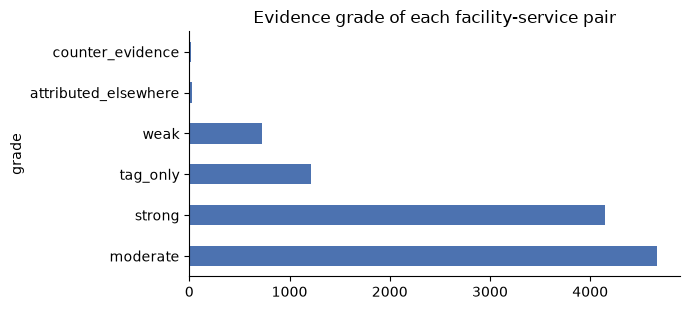

In [13]:
lex = json.loads((ROOT / "kb/taxonomy/lexicon.json").read_text())
rules = pd.read_parquet(V1 / "evidence_rules.parquet")
grades = pd.read_parquet(V1 / "grades.parquet", columns=["grade"])
pathways = json.loads((ROOT / "kb/pathways/care_pathways.json").read_text())["pathways"]
print(f"{len(lex['services'])} services in the taxonomy; {len(rules)} evidence rules from "
      f"{int((rules.handcheck_true + rules.handcheck_false).sum())} hand-checked cases; "
      f"{len(grades):,} facility-service pairs graded.")
print("Care pathways:", "; ".join(p["name"].split(":")[0] for p in pathways))
grades.grade.value_counts().plot.barh(color="#4c72b0", title="Evidence grade of each facility-service pair")
plt.tight_layout()
plt.show()

## 6. The model and an honest evaluation

In plain words: for every facility and service the model adds up points, like a credit scorecard, and turns the
sum into a chance. It has three small scorecards, each a glass box:
- **offers:** does the facility really offer the service? This is the score the app shows (P_S).
- **location:** is the facility at the place the map says (P_L)?
- **exists:** is it a real, working facility (P_E)?

Each row of points comes from a named family of witnesses, for example the listing's own sentences about the
service, text that names another facility, a public list such as NABH or e-RaktKosh, the facility's own website,
or the public standard (IPHS) for a government hospital of that level. The rows on a card add up exactly to its
score; nothing is hidden.

**Fairness coding.** When a source cannot see a facility at all (no website of its own, a list that does not cover
its type, not a public hospital), its family is coded *not observable* and adds 0 points. A missing website never
counts against a small or public facility.

The weights are expert settings derived from audit rates, written down before the labels were read. The shipped
version, **A_platt**, adds one calibration step fitted on the DEV labels: every point is multiplied by the same
factor and one constant is added, so the card stays additive. The cells below read the frozen model card,
`derived/v2/model_card.json`.

In [14]:
card = json.loads((ROOT / "derived/v2/model_card.json").read_text())
FAMILY = {"base": "base rate for the service", "T": "the listing's own text about the service",
          "C": "text that names another facility", "C_prior": "record breadth and operator (contamination prior)",
          "N": "non-offer cue (referral, camp, plan, negation)", "S": "scope (eye, dental, IVF or lab facility)",
          "P": "prerequisites (ICU, theatre, blood bank)", "X": "public and registry lists",
          "W": "the facility's own website", "O": "open data (OpenStreetMap, Wikidata)",
          "D": "dataset details (same text as T)", "K": "public standard (IPHS) for the facility's level",
          "R": "reader slot (weight 0, never fires)", "context": "facility level and type"}
platt = card["service_head"]["platt"]
print("model_version", card["model_version"])
print(f"offers head: {card['selected']} = {card['service_head']['base_scorecard']}, plus one Platt step "
      f"(a {platt['a']:.4f}, c {platt['c']:.4f}; fitted on {platt['fitted_on']})")
print("  what p means:", card["selected_meaning"])
print("location head:", card["location_head"]["shipped"])
print("exists head:", card["existence_head"])
print("labels:", card["label_provenance"]["wording"])
for c in card["caveats"]:
    print(" -", c)
fam = pd.DataFrame(card["per_family_points"])
fam.insert(1, "witness family", fam.family.map(FAMILY))
display(fam.rename(columns={"count": "terms", "min": "lowest points", "max": "highest points"}).set_index("family"))

model_version eed29abe3b7d857800e31103e702da866299739f7d19d13375585bf7dbf1d69a
offers head: A_platt = candidate A expert prior scorecard (fit_prior/prior_a.py), no weight fitted, plus one Platt step (a 0.5020, c 1.4983; fitted on all 221 decided DEV pairs, unweighted)
  what p means: P_S = chance that a web check which finds a decisive answer confirms the service (confirmed vs contradicted; no-information checks excluded). It is not the chance that a phone call finds the service.
location head: A prior scorecard (expert settings)
exists head: prior-only expert settings, not learned (decision; 47 DEV negatives, all 'unclear and searched')
labels: agent-labelled, not human-checked
 - No fairness parity is claimed; public facilities are few and nearly all confirmed in DEV.
 - v1 numbers are history and are not comparable with these DEV numbers.
 - Not-observable sources contribute 0 by construction.
 - Candidate D (reader) was rejected; the reader slot has weight 0 and never fires.


,witness family,terms,lowest points,highest points
family,,,,
C,text that names another facility,2,-7.387,-7.242
C_prior,record breadth and operator (contamination prior),4,-9.356,0.000
D,dataset details (same text as T),1,6.663,6.663
K,public standard (IPHS) for the facility's level,1,7.242,7.242
N,"non-offer cue (referral, camp, plan, negation)",1,-24.189,-24.189
O,"open data (OpenStreetMap, Wikidata)",2,34.107,53.041
P,"prerequisites (ICU, theatre, blood bank)",2,7.242,13.036
R,"reader slot (weight 0, never fires)",1,0.000,0.000
S,"scope (eye, dental, IVF or lab facility)",1,-38.367,-38.367


**How the shipped model was chosen.** The order of candidates and the rule were fixed before any were fitted:
- **A**, the expert prior scorecard;
- **A_platt**, A with one calibration step;
- **B**, a fitted monotone logistic scorecard, and **B_platt**;
- **C**, an explainable boosting machine (an additive glass-box model, interactions off).

The least-fitted candidate ships unless a more-fitted one lowers the out-of-fold log loss by at least one paired
cluster standard error. The headline labels are web checks with a decisive answer: confirmed against contradicted.
The base rate (a constant) is shown as a reference. Further C variants were run as ablations outside the
pre-set order and were not used for selection (`model/v2/final/SELECT.md`).

In [15]:
def ci(v, d=3):
    return f"{v[0]:.{d}f} [{v[1]:.{d}f}, {v[2]:.{d}f}]"


sel, lp = card["selection_headline"], card["label_provenance"]
print("Rule:", card["selection_rule"])
print(re.search(r"Intervals: [^.]+\.", (ROOT / "model/v2/final/SELECT.md").read_text()).group(0))
print(f"Headline labels: {lp['headline']['n']} decided DEV pairs, {lp['headline']['pos']} confirmed and "
      f"{lp['headline']['neg']} contradicted ({lp['wording']}). TEST pairs are excluded from every training row.")
CANDIDATES = ["A", "A_platt", "B", "B_platt", "C", "base_rate"]
display(pd.DataFrame([{"candidate": k, "out-of-fold log loss": ci(m["log_loss"]), "AUROC": ci(m["auroc"]),
                       "Brier": ci(m["brier"]), "ECE": ci(m["ece"])}
                      for k, m in sel["table"].items() if k in CANDIDATES]).set_index("candidate"))
for s in sel["selection"]["steps"]:
    print(f"{s['candidate']} against {s['incumbent']}: log loss {s['diff']:+.3f} (SE {s['se']:.3f}, "
          f"95% {s['ci95'][0]:+.3f} to {s['ci95'][1]:+.3f}): {'replaces' if s['replaces'] else 'does not replace'}")
sens = card["selection_sensitivity"]
print(f"Selected: {sel['selection']['selected']}. With 'searched and found nothing' counted as not offered "
      f"({sens['table']['A']['n']} pairs) the rule selects {sens['selection']['selected']} too.")

Rule: ship the least-fitted of A < A_platt < B < B_platt < C unless a more-fitted one lowers grouped 5-fold OOF log loss by at least one paired cluster SE
Intervals: 95% group bootstrap over leakage groups (2,000).
Headline labels: 221 decided DEV pairs, 168 confirmed and 53 contradicted (agent-labelled, not human-checked). TEST pairs are excluded from every training row.


,out-of-fold log loss,AUROC,Brier,ECE
candidate,,,,
A,"0.723 [0.598, 0.861]","0.804 [0.725, 0.869]","0.234 [0.195, 0.276]","0.230 [0.185, 0.291]"
A_platt,"0.427 [0.352, 0.515]","0.800 [0.720, 0.867]","0.132 [0.105, 0.164]","0.044 [0.027, 0.103]"
B,"0.451 [0.353, 0.560]","0.813 [0.742, 0.879]","0.143 [0.109, 0.178]","0.074 [0.041, 0.134]"
B_platt,"0.432 [0.355, 0.518]","0.812 [0.741, 0.879]","0.138 [0.110, 0.170]","0.053 [0.025, 0.108]"
C,"0.461 [0.386, 0.551]","0.766 [0.683, 0.841]","0.146 [0.118, 0.178]","0.043 [0.025, 0.106]"
base_rate,"0.557 [0.490, 0.630]","0.413 [0.328, 0.505]","0.184 [0.154, 0.217]","0.068 [0.035, 0.125]"


A_platt against A: log loss -0.296 (SE 0.059, 95% -0.413 to -0.184): replaces
B against A_platt: log loss +0.024 (SE 0.035, 95% -0.046 to +0.093): does not replace
B_platt against A_platt: log loss +0.005 (SE 0.026, 95% -0.048 to +0.056): does not replace
C against A_platt: log loss +0.035 (SE 0.027, 95% -0.019 to +0.086): does not replace
Selected: A_platt. With 'searched and found nothing' counted as not offered (470 pairs) the rule selects A_platt too.


**Calibration, bands and how many to call.** A score should come true about as often as it says. The table puts
the DEV pairs into score bins and compares the mean score with the share that was confirmed. The app shows
words, not raw scores: LIKELY, CALL FIRST, NO SERVICE TEXT or UNLIKELY, from thresholds chosen on DEV. Conformal
top-k says how many options to list so that a confirmed facility is among them most of the time.

,n_decided,k_confirmed,k_contradicted,mean_p,confirmed share,95% interval
score bin,,,,,,
0.0 to 0.2,7,0,7,0.168,0.000,0.00 to 0.35
0.2 to 0.4,17,5,12,0.316,0.294,0.13 to 0.53
0.4 to 0.6,22,11,11,0.535,0.500,0.31 to 0.69
0.6 to 0.8,47,38,9,0.697,0.809,0.67 to 0.90
0.8 to 1.0,128,114,14,0.913,0.891,0.82 to 0.93


note: bins on DEV OOF P_S for decided pairs and on the shipped P_S for undecided pairs


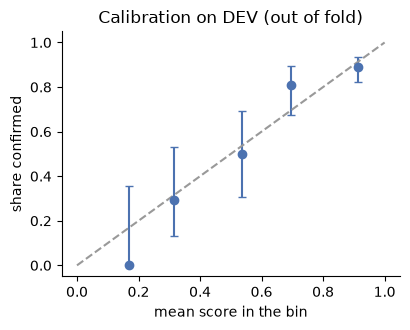

LIKELY needs p >= 0.3686, location >= 0.7 and exists >= 0.7. On DEV: 102 of 120 LIKELY pairs confirmed (95% 0.775 to 0.903).
UNLIKELY needs p <= 0.20 (fallback value). On DEV: 7 of 7 UNLIKELY pairs contradicted (95% 0.646 to 1.000).
rule: LIKELY: p >= t_L, P_L and P_E >= 0.7, T >= 2. UNLIKELY: p <= t_U, or C = 2 with T <= 1 (the c2 term). Otherwise CALL_FIRST when T >= 2, else NO_SERVICE_TEXT.
model, all scored pairs by band (frozen; every service): NO_SERVICE_TEXT 242,131, UNLIKELY 94,217, LIKELY 20,073, CALL_FIRST 1,671 (of 358,092)
conformal top-k, emergency (trauma_care, emergency_24x7, emergency_csection, burn_care, stemi_thrombolysis, nicu): list k = 2; a confirmed facility is among them in 27 of 27 DEV queries (95% from 0.88); a random order of the same lists reaches 0.97
conformal top-k, planned (dialysis, mri, cardiac_surgery): list k = 2; a confirmed facility is among them in 19 of 20 DEV queries (95% from 0.76); a random order of the same lists reaches 0.97
note: Pseudo-quer

In [16]:
cal = pd.DataFrame(card["calibration_by_score_bin"])
cal["confirmed share"] = cal.k_confirmed / cal.n_decided
cal["95% interval"] = cal.wilson95.map(lambda w: f"{w[0]:.2f} to {w[1]:.2f}")
cal["score bin"] = cal.apply(lambda r: f"{r.p_min:.1f} to {r.p_max:.1f}", axis=1)
display(cal.set_index("score bin")[["n_decided", "k_confirmed", "k_contradicted", "mean_p", "confirmed share",
                                    "95% interval"]].round(3))
print("note:", card["calibration_note"])
fig, ax = plt.subplots(figsize=(4.2, 3.4))
err = [cal["confirmed share"] - cal.wilson95.map(min), cal.wilson95.map(max) - cal["confirmed share"]]
ax.errorbar(cal.mean_p, cal["confirmed share"], yerr=err, fmt="o", color="#4c72b0", capsize=3)
ax.plot([0, 1], [0, 1], ls="--", color="#999999")
ax.set_xlabel("mean score in the bin")
ax.set_ylabel("share confirmed")
ax.set_title("Calibration on DEV (out of fold)")
plt.tight_layout()
plt.show()

th, bt = card["thresholds"], card["band_thresholds"]
lk, ul = th["likely"], th["unlikely"]
print(f"LIKELY needs p >= {bt['likely']['p']:.4f}, location >= {bt['likely']['p_location']} and exists >= "
      f"{bt['likely']['p_exists']}. On DEV: {lk['k_correct']} of {lk['n']} LIKELY pairs confirmed "
      f"(95% {lk['wilson95'][0]:.3f} to {lk['wilson95'][1]:.3f}).")
print(f"UNLIKELY needs p <= {bt['unlikely']['p']:.2f}{' (fallback value)' if th['t_U_fallback'] else ''}. On DEV: "
      f"{ul['k_correct']} of {ul['n']} UNLIKELY pairs contradicted (95% {ul['wilson95'][0]:.3f} to {ul['wilson95'][1]:.3f}).")
print("rule:", bt["rule"])
bands = card["bands_all_pairs"]
print("model, all scored pairs by band (frozen; every service):", ", ".join(f"{k} {v:,}" for k, v in bands.items()),
      f"(of {sum(bands.values()):,})")
for urgency, c in card["conformal"].items():
    print(f"conformal top-k, {urgency} ({', '.join(c['services'])}): list k = {c['k']}; a confirmed facility is "
          f"among them in {c['coverage_k']} of {c['n_queries']} DEV queries (95% from {c['coverage_wilson95'][0]:.2f}); "
          f"a random order of the same lists reaches {c['random_order_coverage']:.2f}")
print("note:", card["conformal_note"])

**Public and private facilities.** Public facilities are few in the labels and nearly all confirmed, so we cannot
measure how well the score ranks them. The sentence below is the wording agreed on #79, with the numbers read
from the model card.

In [17]:
pvp = card["public_vs_private"]
pub = pvp["public"]
print(f"On {pub['n']} labelled public pairs ({pub['contradicted']} contradicted) we could not show that the score "
      "ranks public facilities better than chance; the sample is too small to tell.")
print()
for op in ("public", "private"):
    m = pvp[op]["metrics"][card["selected"]]
    print(f"{op:8} {pvp[op]['n']:>4} pairs ({pvp[op]['confirmed']} confirmed, {pvp[op]['contradicted']} contradicted): "
          f"AUROC {ci(m['auroc'], 2)}, log loss {ci(m['log_loss'], 2)}")

On 31 labelled public pairs (3 contradicted) we could not show that the score ranks public facilities better than chance; the sample is too small to tell.

public     31 pairs (28 confirmed, 3 contradicted): AUROC 0.39 [0.07, 0.80], log loss 0.44 [0.24, 0.70]
private   186 pairs (137 confirmed, 49 contradicted): AUROC 0.82 [0.75, 0.89], log loss 0.43 [0.35, 0.52]


**One worked example.** The full ledger of one real pair, Sadar Hospital Gopalganj (a district hospital in Bihar;
its record name is printed below) for dialysis, read from `derived/v2/facility_service_scores.parquet`. Each row is
a witness with its points; the base and the rows add up to the score, which is checked below. `lo` and `hi` are the track record of the score bin
(the share confirmed among DEV pairs in the same bin), not an interval around p.

In [18]:
scores = pd.read_parquet(ROOT / "derived/v2/facility_service_scores.parquet")
names = pd.read_parquet(V1 / "facility_location.parquet", columns=["unique_id", "name", "district"])
rec = names[names.name.str.contains("Sadar Hospital", na=False) & names.district.str.upper().eq("GOPALGANJ")]
assert len(rec) == 1, "the worked example should name exactly one record"
row = scores[scores.unique_id.eq(rec.unique_id.iloc[0]) & scores.service_id.eq("dialysis")].iloc[0]
PTS = card["per_term_weights"][0]["shipped_points"] / card["per_term_weights"][0]["shipped_logit"]  # points per logit
ledger = pd.DataFrame(json.loads(row.contributions))
ledger.insert(1, "witness family", ledger.family.map(FAMILY))
ledger["evidence"] = ledger.evidence_ids.map(len)
base_pts = row.base * PTS
total = base_pts + ledger.points.sum()
p_from_ledger = 1 / (1 + math.exp(-total / PTS))
print(f"{rec.name.iloc[0]} ({rec.district.iloc[0].title()}), dialysis: {row.band} {list(row.overlays)}, "
      f"operator {row.operator}")
with pd.option_context("display.max_colwidth", 70):
    display(ledger[["label", "witness family", "card_phrase", "evidence", "points"]].round(1))
print(f"base {base_pts:+.1f} + rows {ledger.points.sum():+.1f} = {total:+.1f} points; "
      f"p = 1 / (1 + exp(-points / {PTS:.2f})) = {p_from_ledger:.4f}; stored p = {row.p:.4f}")
assert abs(p_from_ledger - row.p) < 1e-9
print(f"location P_L {row.p_location:.3f}, exists P_E {row.p_exists:.3f}; score-bin track record {row.lo:.2f} to {row.hi:.2f}")

Rastra Kavi Dinkar Blood Bank, Sadar Hospital (Gopalganj), dialysis: LIKELY ['PLACE_UNCLEAR'], operator public


,label,witness family,card_phrase,evidence,points
0,t1,the listing's own text about the service,"the listing mentions it, at least in a specialty tag or list",7,6.5
1,t2,the listing's own text about the service,the listing describes it as its own unit,7,12.2
2,t3,the listing's own text about the service,two or more own units in one field,7,11.6
3,t4,the listing's own text about the service,own units in two or more fields,7,14.5
4,t5,the listing's own text about the service,own units in several fields plus a unit or quantity,7,8.7
5,tb_high,record breadth and operator (contamination prior),record built from 30+ web pages (some text may be another facility's),0,-9.4
6,tp_public,record breadth and operator (contamination prior),public facility: listing text is less often its own,0,-2.8
7,c1,text that names another facility,some text names another facility,1,-7.4
8,p1,"prerequisites (ICU, theatre, blood bank)","a prerequisite (ICU, operating theatre, blood bank) is mentioned",1,13.0
9,k_iphs,public standard (IPHS) for the facility's level,the public standard (IPHS) says this level should offer it,1,7.2


base +1.2 + rows +61.4 = +62.6 points; p = 1 / (1 + exp(-points / 28.85)) = 0.8975; stored p = 0.8975
location P_L 0.716, exists P_E 0.832; score-bin track record 0.82 to 0.93


**The frozen TEST.** Before any TEST label was read, the model was frozen: its version is a hash of the
parameters, thresholds and code, and its predictions for the sealed TEST pairs were committed with their SHA-256.
The TEST labels are web checks by agents, like DEV, so they are agent-labelled, not human-checked. TEST was opened
once, after the freeze; the cell checks both hashes and reads `model/gold/v3/test_eval/results.json`. The headline
metric is confirmed against contradicted.

Cleaning (section 3) already fixed duplicates, impossible or out-of-country map points and misplaced points. What
the model is left with is mostly claims that nobody can settle from the web (the "no decisive answer" share below)
and the phone and opening-hours facts that no listing carries. That is why the app's default is "call first".

In [19]:
pred = ROOT / "model/v2/test_predictions.parquet"
sealed_sha = (ROOT / "model/v2/test_predictions.sha256").read_text().split()[0]
tp = pd.read_parquet(pred, columns=["pair_id", "model_version"])
print("model_version (model_card.json):", card["model_version"])
print(f"TEST predictions: {len(tp)} pairs, sha256 {sealed_sha}")
print("bytes match the committed sha256:", hashlib.sha256(pred.read_bytes()).hexdigest() == sealed_sha,
      "| written by this model_version:", set(tp.model_version) == {card["model_version"]})
TEST_EVAL = ROOT / "model/gold/v3/test_eval/results.json"
if not TEST_EVAL.is_file():
    print("TEST is sealed and not yet opened.")
else:
    te = json.loads(TEST_EVAL.read_text())
    assert te["model_version"] == card["model_version"] and te["test_predictions_sha256"] == sealed_sha
    print(f"Opened once, against these predictions (model/gold/v3/OPENING_LOG.md). {te['about']}")
    v = te["verdicts"]
    n_all = sum(v.values())
    print(f"Verdicts: {v['confirmed']} confirmed, {v['contradicted']} contradicted, and {v['no_info']} of {n_all} "
          f"({v['no_info'] / n_all:.0%}) with no decisive answer on the web.")

    def test_row(name, m):
        lk = m["LIKELY_confirmed"]
        return {"TEST pairs": name, "n": m["n"], "confirmed": m["confirmed"], "contradicted": m["contradicted"],
                "AUROC": f"{m['auroc']:.3f} [{m['auroc_ci95'][0]:.3f}, {m['auroc_ci95'][1]:.3f}]",
                "log loss": f"{m['log_loss']:.3f} [{m['log_loss_ci95'][0]:.3f}, {m['log_loss_ci95'][1]:.3f}]",
                "base-rate log loss": m["base_rate_log_loss"], "Brier": m["brier"], "ECE": m["ece5"],
                "LIKELY confirmed": f"{lk['k']} of {lk['n']}" + (f" ({lk['rate']:.3f} [{lk['ci95'][0]:.3f}, "
                                                                f"{lk['ci95'][1]:.3f}])" if lk["n"] else "")}

    ops, meth = te["by_operator_decided"], te["by_method_decided"]
    display(pd.DataFrame([test_row("headline: all decided", te["headline_decided"]),
                          *(test_row(f"{op} (decided)", ops[op]) for op in ("public", "private")),
                          *(test_row(f"labelled by {k} (decided)", m) for k, m in meth.items()),
                          test_row("sensitivity: no decisive answer = not offered", te["sensitivity_no_info_as_0"])])
            .set_index("TEST pairs"))
    pub = ops["public"]
    print(f"Public facilities: {pub['n']} decided pairs, AUROC interval {pub['auroc_ci95'][0]:.3f} to "
          f"{pub['auroc_ci95'][1]:.3f}: " + ("ranking shown." if pub["auroc_ci95"][0] > 0.5 else
                                          "it includes 0.5, so ranking public facilities is not shown."))

model_version (model_card.json): eed29abe3b7d857800e31103e702da866299739f7d19d13375585bf7dbf1d69a
TEST predictions: 150 pairs, sha256 1b85f4c81afd936a057d9349247c716f7fa65091931d51e30ccdcef83f6e3ff4
bytes match the committed sha256: True | written by this model_version: True
Opened once, against these predictions (model/gold/v3/OPENING_LOG.md). Gold v3 TEST, opened once (OPENING_LOG.md), against frozen model v2 predictions. Agent-labelled, not human-checked.
Verdicts: 47 confirmed, 13 contradicted, and 90 of 150 (60%) with no decisive answer on the web.


,n,confirmed,contradicted,AUROC,log loss,base-rate log loss,Brier,ECE,LIKELY confirmed
TEST pairs,,,,,,,,,
headline: all decided,60,47,13,"0.819 [0.686, 0.924]","0.406 [0.295, 0.529]",0.523,0.132,0.068,"25 of 28 (0.893 [0.728, 0.963])"
public (decided),25,19,6,"0.759 [0.491, 0.958]","0.456 [0.260, 0.711]",0.551,0.147,0.032,"11 of 12 (0.917 [0.646, 0.985])"
private (decided),33,26,7,"0.852 [0.681, 0.970]","0.386 [0.262, 0.521]",0.517,0.128,0.123,"13 of 15 (0.867 [0.621, 0.963])"
labelled by fetch_only (decided),12,7,5,"0.829 [0.531, 1.000]","0.518 [0.256, 0.802]",0.679,0.182,0.169,"5 of 6 (0.833 [0.436, 0.970])"
labelled by search (decided),48,40,8,"0.816 [0.630, 0.954]","0.378 [0.258, 0.517]",0.451,0.119,0.095,"20 of 22 (0.909 [0.722, 0.975])"
sensitivity: no decisive answer = not offered,150,47,103,"0.687 [0.590, 0.780]","1.046 [0.902, 1.195]",0.622,0.361,0.407,"25 of 63 (0.397 [0.285, 0.520])"


Public facilities: 25 decided pairs, AUROC interval 0.491 to 0.958: it includes 0.5, so ranking public facilities is not shown.


**What the TEST does and does not show.** The lead number is the Likely band: how often a Likely answer was
confirmed. AUROC says how well the score orders options within a list. Two checks read the same TEST labels
(`model/gold/v3/test_eval/independence.json`, written by `independence.py`, read-only on the frozen predictions):
- **Independence.** When the facility's own website states the service, the model's website witness and the web
  check read the same page, so agreement there is expected. The split shows how the score does without it.
- **Bands, exists and Unlikely.** Each band's verdicts, the existence head (TEST has no "does not exist" label, so
  the DEV rule counts "unclear after a search" as a negative), and Unlikely by its two routes: a low score, or the
  c2 rule (text names another facility and no unit of its own).

In [20]:
ind = json.loads((ROOT / "model/gold/v3/test_eval/independence.json").read_text())
assert ind["test_predictions_sha256"] == sealed_sha and ind["overall"]["auroc"] == te["headline_decided"]["auroc"]


def auc_txt(m):
    return "undefined (no contradicted pair)" if m["auroc"] is None else         f"{m['auroc']:.3f} [{m['auroc_ci95'][0]:.3f}, {m['auroc_ci95'][1]:.3f}]"


display(pd.DataFrame(ind["bands"]).assign(**{"confirmed of decided": lambda d: d.confirmed_of_decided.map(
    lambda w: f"{w['k']} of {w['n']}" if w["n"] else "-")}).set_index("band")[
    ["pairs", "confirmed", "contradicted", "no_info", "no_info_share", "confirmed of decided"]])
w = ind["by_website_family"]
print(f"Own website states the service (W > 0): {w['W_gt_0']['confirmed']} of {w['W_gt_0']['n']} confirmed. "
      f"Website silent or absent (W <= 0): {w['W_le_0']['n']} pairs, AUROC {auc_txt(w['W_le_0'])}.")
for k, m in ind["by_label_evidence_source"].items():
    if isinstance(m, dict) and m["n"] >= 5:
        print(f"Label evidence from {k.replace('_', ' ')}: {m['n']} pairs, AUROC {auc_txt(m)}")
b = ind["band_as_score"]
print(f"The band as a score: AUROC {auc_txt(b['band_ordinal'])}; LIKELY against the rest {auc_txt(b['likely_vs_rest'])}")
print("Services with no contradicted TEST pair:", ", ".join(ind["services_with_0_test_negatives"]))
ex = ind["existence_head"]
print(f"Exists: labels {ex['counts']}; with the DEV rule, AUROC {auc_txt(ex['y_E_rule'])}")
for split, r in ind["unlikely_by_route"].items():
    if split != "t_U":
        print(f"{split} Unlikely right (contradicted): p <= {ind['unlikely_by_route']['t_U']} route "
              f"{r['p_route']['k']} of {r['p_route']['n']}, c2 route {r['c2_route']['k']} of {r['c2_route']['n']}"
              + (" (DEV is the fit set)" if split == "DEV" else ""))
labels = {k: json.loads((ROOT / f"model/gold/v3/{k}_labels.json").read_text())["report"]["overlap"]
          for k in ("dev", "test")}
print(f"Label agreement (Cohen's kappa on the verdict): DEV {labels['dev']['kappa_service']}, TEST "
      f"{labels['test']['kappa_service']}; TEST confirmed-vs-contradicted disagreements: "
      f"{sum(v for k, v in labels['test']['confusion'].items() if set(k.split('|')) == {'confirmed', 'contradicted'})}")

,pairs,confirmed,contradicted,no_info,no_info_share,confirmed of decided
band,,,,,,
LIKELY,63,25,3,35,0.556,25 of 28
CALL_FIRST,11,0,0,11,1.000,-
NO_SERVICE_TEXT,72,20,8,44,0.611,20 of 28
UNLIKELY,4,2,2,0,0.000,2 of 4


Own website states the service (W > 0): 21 of 21 confirmed. Website silent or absent (W <= 0): 39 pairs, AUROC 0.703 [0.521, 0.864].
Label evidence from record source: 39 pairs, AUROC 0.894 [0.768, 0.988]
Label evidence from independent domain: 19 pairs, AUROC 0.705 [0.400, 0.945]
The band as a score: AUROC 0.670 [0.509, 0.813]; LIKELY against the rest 0.651 [0.507, 0.778]
Services with no contradicted TEST pair: emergency_24x7, emergency_csection, nicu, stemi_thrombolysis
Exists: labels {'yes': 114, 'unclear': 36}; with the DEV rule, AUROC 0.617 [0.484, 0.749]
TEST Unlikely right (contradicted): p <= 0.2 route 2 of 2, c2 route 0 of 2
DEV Unlikely right (contradicted): p <= 0.2 route 7 of 7, c2 route 3 of 8 (DEV is the fit set)
Label agreement (Cohen's kappa on the verdict): DEV 0.834, TEST 0.624; TEST confirmed-vs-contradicted disagreements: 0


**A negative result: the reader.** We fine-tuned a small transformer to read each sentence and say whether it is
about this facility and whether it offers the service. We trained MiniLM on the lead's Mac, and bge-small and
multilingual-e5 on a Databricks GPU. On "is this sentence about this facility", two readers score a little
above the rules, but no interval of the difference (the F1 on label 0, paired bootstrap) is above zero, so no gain
is shown. On "offers" every reader is far worse. So the model keeps the rules and the reader slot has weight 0.

In [21]:
RD = ROOT / "model/reader"
mac = json.loads((RD / "out/metrics_full.json").read_text())
gpu = json.loads((RD / "out_gpu/metrics_gpu_remaining.json").read_text())
gpu_name = re.search(r"NVIDIA [A-Z0-9]+", (RD / "out_gpu/nvidia_smi.txt").read_text()).group(0)
rules = mac["rules_on_hand_labels"]
out = [{"system": "rules (the bar)", "where": "-", "about_this F1": rules["about_this"]["class_0"]["f1"],
        "about_this minus rules": "-", "offers F1": rules["offers"]["class_0"]["f1"], "offers minus rules": "-"}]
for run, where in ((mac, f"{mac['hardware']['cpu']}, MPS"), (gpu, f"Databricks, {gpu_name}")):
    for name, r in run["runs"].items():
        row = {"system": name, "where": where}
        for head in ("about_this", "offers"):
            v = r["hand_labels"][head]
            d = v["reader_vs_rules"]["class_0"]
            row[f"{head} F1"] = v["reader"]["class_0"]["f1"]
            row[f"{head} minus rules"] = (f"{d['f1_reader_minus_rules']:+.3f} [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]"
                                          + (" beats" if d["ci95"][0] > 0 else ""))
        out.append(row)
print(f"F1 on label 0 (about another facility / not an offer), {mac['eval_rows']} hand-labelled sentences; "
      "bracket = 95% paired bootstrap interval of reader minus rules")
display(pd.DataFrame(out).set_index("system"))
print("model card:", next(c for c in card["caveats"] if "reader" in c))

F1 on label 0 (about another facility / not an offer), 564 hand-labelled sentences; bracket = 95% paired bootstrap interval of reader minus rules


,where,about_this F1,about_this minus rules,offers F1,offers minus rules
system,,,,,
rules (the bar),-,0.547,-,0.864,-
minilm-l12,"Apple M5 Pro, MPS",0.578,"+0.031 [-0.077, +0.139]",0.354,"-0.510 [-0.653, -0.375]"
bge-small,"Databricks, NVIDIA A10G",0.597,"+0.050 [-0.065, +0.170]",0.452,"-0.412 [-0.551, -0.285]"
me5-small,"Databricks, NVIDIA A10G",0.519,"-0.028 [-0.140, +0.091]",0.333,"-0.531 [-0.665, -0.392]"


model card: Candidate D (reader) was rejected; the reader slot has weight 0 and never fires.


## 7. `recommend(service, location)`: the answer, its WHY and its HOW

This is the same code the app serves at `POST /api/plan`, imported from `app/`:
- `facts.engine.Engine`: the scores, bands and evidence for each facility and service;
- `itinerary`: the multi-stop route from `planner/`.

For each option it prints:
- the band in words, the score with its range, and the travel estimate;
- the listing's own sentences, word for word, with their ids;
- the points that add up to the score;
- the question to ask on the phone.

In [22]:
from facts.engine import Engine
from itinerary import attach

ENGINE = Engine.load()
print(f"engine loaded: {len(ENGINE.fid):,} facilities, {sum(len(v) for v in ENGINE.pairs.values()):,} "
      f"facility-service pairs the app serves, {len(ENGINE.claims):,} quotable sentences; data {ENGINE.meta['source']} "
      f"as of {ENGINE.meta['as_of']}")

def recommend(service: str, lat: float, lon: float) -> dict:
    """The /api/plan payload for a service at a point (rounded to about 1 km, as the app does)."""
    return attach(ENGINE.plan(service, round(lat, 2), round(lon, 2), None, "notebook"), ENGINE)

def show(plan: dict, n: int = 3) -> None:
    label = plan["query"]["service_label"]["en"]
    print(f"== {label} near {plan['location']['lat']}, {plan['location']['lon']}")
    if plan["abstain"]:
        print("   SAYS NO:", plan["abstain"]["text"])
    for o in plan["options"][:n]:
        t = o["travel"]
        print(f"\n{o['rank']}. {o['name']} ({o['district']}, {o['state']})")
        rng = "similar scores confirmed" if o["range_kind"] == "similar_scores" else "range"
        print(f"   {o['band_word'].upper()}: score {o['p']:.2f} ({rng} {o['p_lo']:.2f} to {o['p_hi']:.2f}); "
              f"{t['km']:.0f} km, about {t['low']}-{t['high']} min ({t['label']})")
        for e in o["evidence"][:2]:
            print(f'   WHY  "{e["quote"]}"  [{e["claim_id"]}]')
        pts = " + ".join(f"{c['label']} {c['points']:+g}" for c in o["contributions"])
        print(f"   HOW  {pts} = {sum(c['points'] for c in o['contributions']):+g} points")
        if o.get("why_first_text"):
            print("   FIRST", o["why_first_text"])
        print("   ASK ", o["call_ahead"][0]["question"])
    it = plan.get("itinerary")
    if it and it["plans"]:
        r = it["plans"][0]
        print(f"\n   ROUTE ({it['pathway_name']}): {r['type_word']}")
        for k, s in enumerate(r["stops"], 1):
            print(f"   {k}. {s['purpose_word']}: {s['name']}, arrive about {s['eta_low']}-{s['eta_high']} min, "
                  f"chance {s['p']:.2f}, {s['n_evidence']} evidence lines")
        if r["vs_direct"]:
            v = r["vs_direct"]
            print("  ", v["text"])

engine loaded: 9,947 facilities, 7,618 facility-service pairs the app serves, 42,801 quotable sentences; data derived/v1 as of 2026-11-21


In [23]:
show(recommend("dialysis", 24.79, 85.0))          # Gaya, Bihar

== dialysis near 24.79, 85.0

1. Arsh Superspeciality Hospital (GAYA, BIHAR)
   LIKELY: score 0.99 (similar scores confirmed 0.82 to 0.93); 2 km, about 2-3 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Dialysis"  [242efdf5:proc:15]
   HOW  Starting score, the same for every listing +0.4 + Its listing names it, at least in a specialty tag or list +2.3 + Its listing describes it as a service of its own +4.2 + Record built from many web pages; some text may be another facility's -2.1 + It names something this care needs, such as an ICU, operating theatre or blood bank +4.5 + NABH list: it has this service's code +20.9 + Its own website says so clearly, on 2 or more pages +20.9 + Website and listing share pages, so that part counts once -6.5 + 100 or more beds +2.5 + 20 or more specialties listed +1.5 = +48.6 points
   ASK  Is dialysis unit or machine available today for this patient?

2. Buddha Hospital and Research Institute (GAYA, BIHAR)
   LIKELY: score

In [24]:
show(recommend("emergency_csection", 19.88, 75.34))   # Aurangabad district, Maharashtra

== emergency C-section near 19.88, 75.34

1. United CIIGMA Hospital (AURANGABAD, MAHARASHTRA)
   LIKELY: score 0.88 (similar scores confirmed 0.82 to 0.93); 3 km, about 3-6 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Offers labour analgesia and Caesarean sections"  [231f141f:proc:14]
   HOW  Starting score, the same for every listing +0.4 + Its listing names it, at least in a specialty tag or list +2.3 + Its listing describes it as a service of its own +4.2 + Record built from 30 or more web pages; some text may be another facility's -3.2 + It names something this care needs, such as an ICU, operating theatre or blood bank +4.5 + It names a second thing this care needs +2.5 + NABH list: it has this department +12.9 + Its website works but does not mention it -7.4 + 100 or more beds +2.5 + 20 or more specialties listed +1.5 = +20.2 points
   FIRST Nearest place that plausibly offers it first; call first, and if they say no, call the next.
   ASK  What 

In [25]:
show(recommend("trauma_emergency", 24.79, 85.0))      # road accident near Gaya, Bihar: a multi-stop plan

== accident and injury care near 24.79, 85.0

1. Dr. A Barkat Multispeciality Hospital (GAYA, BIHAR)
   LIKELY: score 0.96 (similar scores confirmed 0.82 to 0.93); 0 km, about 0-1 min (rough estimate: straight line x 1.34 at 49 km/h, no route check)
   WHY  "Provides 24/7 trauma and emergency care"  [f115e7cd:capa:15]
   WHY  "Operates 24/7 emergency care"  [f115e7cd:capa:18]
   HOW  Starting score, the same for every listing +0.4 + Its listing names it, at least in a specialty tag or list +2.3 + Its listing describes it as a service of its own +4.2 + It names something this care needs, such as an ICU, operating theatre or blood bank +4.5 + It names a second thing this care needs +2.5 + Its own website says so clearly, on 2 or more pages +21 + Website and listing share pages, so that part counts once -6.5 + 100 or more beds +2.5 = +30.9 points
   FIRST Nearest place that plausibly offers it first; call first, and if they say no, call the next.
   ASK  Is emergency 24x7 available today 

## 7b. What we compared against: not the nearest, not the unreachable best

The organizers clarified the impact criterion (#86): a tool that always sends people to the closest place is not
impactful, because it ignores everything else, and one that sends them to the best place on paper is not actionable
if they cannot reach it. So we compare the app with both, in two ways:
- **A simulated referral world** (`sim/`, #92). Each simulated world decides in secret which listings are true,
  simulated patients go through each referral policy (call, travel, turned away, try the next), and we count who
  reaches care within the time window. Several truth scenarios are always shown together, because one drawn from the
  model's own score would favour the app by construction. Everything from it is labelled SIMULATED.
- **Real data at the demo places** (`validation/policy_compare.py`, #93): the facility each policy picks first, its
  travel time against the service's window, and the published DEV label where one exists.

In [26]:
# The committed aggregate of the appendix run (submission/02_simulation.ipynb), so this cell needs no simulation
# output folder. Its header gives the seeds, cases and commit.
SIM_TABLE = ROOT / "submission/sim_results.csv"
sim = pd.read_csv(SIM_TABLE, comment="#")
assert sim.label.eq("SIMULATED").all() and sim.n_seeds.nunique() == 1
sim = sim.assign(v=[f"{r.treated_in_window:.2f} [{r.treated_in_window_lo:.2f}, {r.treated_in_window_hi:.2f}]"
                    for r in sim.itertuples()])
print(f"SIMULATED, not field results ({SIM_TABLE.relative_to(ROOT)}, run in submission/02_simulation.ipynb): "
      f"{sim.n_seeds.iloc[0]} seeds, {sim.n_cases.iloc[0]:,} simulated patients per policy, scenario and service,")
print("Bihar and Uttar Pradesh. Share treated within the time window (60 min trauma, 120 min dialysis), 90% "
      "seed-bootstrap interval.")
print("S0-high and S0-low are base-rate bounds: read them together, never one alone. app_before_101 is the "
      "emergency order before #101.")
rows = pd.MultiIndex.from_frame(sim[["service", "policy"]].drop_duplicates())
display(sim.pivot_table(index=["service", "policy"], columns="scenario", values="v", aggfunc="first")  # noqa: F821
        .reindex(rows))
gap = sim[sim.service.eq("trauma_emergency") & sim.policy.isin(["app_before_101", "app"])]
gap = gap.assign(pts=[f"{100 * r.minus_ncf:+.1f} [{100 * r.minus_ncf_lo:+.1f}, {100 * r.minus_ncf_hi:+.1f}]"
                      for r in gap.itertuples()])
print("SIMULATED. Trauma, app minus nearest + call first, in points (paired by seed, 90% interval), before and "
      "after #101:")
display(gap.pivot_table(index="policy", columns="scenario", values="pts", aggfunc="first")  # noqa: F821
        .reindex(["app_before_101", "app"]))

SIMULATED, not field results (submission/sim_results.csv, run in submission/02_simulation.ipynb): 20 seeds, 8,000 simulated patients per policy, scenario and service,
Bihar and Uttar Pradesh. Share treated within the time window (60 min trauma, 120 min dialysis), 90% seed-bootstrap interval.
S0-high and S0-low are base-rate bounds: read them together, never one alone. app_before_101 is the emergency order before #101.


scenario                                       S0-high             S0-low  \
service          policy                                                     
dialysis         app                 0.86 [0.86, 0.87]  0.54 [0.52, 0.56]   
                 app_before_101      0.86 [0.86, 0.87]  0.54 [0.52, 0.56]   
                 app_offline         0.87 [0.87, 0.88]  0.53 [0.51, 0.56]   
                 nearest_call_first  0.87 [0.86, 0.88]  0.53 [0.51, 0.56]   
                 nearest             0.86 [0.85, 0.87]  0.51 [0.49, 0.54]   
                 best_on_paper       0.24 [0.21, 0.26]  0.11 [0.07, 0.15]   
trauma_emergency app                 0.69 [0.68, 0.70]  0.20 [0.18, 0.22]   
                 app_before_101      0.63 [0.62, 0.64]  0.17 [0.16, 0.19]   
                 app_offline         0.70 [0.70, 0.71]  0.21 [0.20, 0.23]   
                 nearest_call_first  0.70 [0.69, 0.71]  0.21 [0.20, 0.23]   
                 nearest             0.70 [0.69, 0.71]  0.21 [0.19, 0.22]   
                 best_on_paper       0.06 [0.05, 0.07]  0.01 [0.01, 0.02]   

scenario                                            S1                 S2  \
service          policy                                                     
dialysis         app                 0.80 [0.78, 0.81]  0.86 [0.85, 0.87]   
                 app_before_101      0.80 [0.78, 0.82]  0.86 [0.85, 0.87]   
                 app_offline         0.77 [0.75, 0.79]  0.86 [0.85, 0.87]   
                 nearest_call_first  0.77 [0.74, 0.79]  0.86 [0.85, 0.87]   
                 nearest             0.75 [0.73, 0.77]  0.85 [0.84, 0.86]   
                 best_on_paper       0.26 [0.25, 0.26]  0.24 [0.21, 0.26]   
trauma_emergency app                 0.61 [0.60, 0.62]  0.67 [0.66, 0.68]   
                 app_before_101      0.57 [0.56, 0.59]  0.62 [0.61, 0.63]   
                 app_offline         0.60 [0.59, 0.61]  0.68 [0.67, 0.69]   
                 nearest_call_first  0.60 [0.59, 0.61]  0.68 [0.67, 0.69]   
                 nearest             0.60 [0.59, 0.62]  0.68 [0.67, 0.69]   
                 best_on_paper       0.06 [0.05, 0.07]  0.06 [0.05, 0.07]   

scenario                                            S3  
service          policy                                 
dialysis         app                 0.76 [0.74, 0.77]  
                 app_before_101      0.76 [0.74, 0.77]  
                 app_offline         0.76 [0.74, 0.77]  
                 nearest_call_first  0.76 [0.74, 0.77]  
                 nearest             0.75 [0.73, 0.76]  
                 best_on_paper       0.24 [0.21, 0.26]  
trauma_emergency app                 0.57 [0.56, 0.58]  
                 app_before_101      0.52 [0.51, 0.54]  
                 app_offline         0.58 [0.57, 0.60]  
                 nearest_call_first  0.58 [0.57, 0.59]  
                 nearest             0.59 [0.57, 0.60]  
                 best_on_paper       0.06 [0.05, 0.07]

SIMULATED. Trauma, app minus nearest + call first, in points (paired by seed, 90% interval), before and after #101:


scenario,S0-high,S0-low,S1,S2,S3
policy,,,,,
app_before_101,"-7.5 [-8.7, -6.4]","-4.1 [-5.1, -3.2]","-2.8 [-3.8, -1.9]","-6.0 [-7.0, -4.9]","-6.2 [-7.1, -5.1]"
app,"-1.7 [-2.3, -1.1]","-1.5 [-2.2, -0.8]","+1.0 [+0.3, +1.7]","-1.0 [-1.5, -0.5]","-1.3 [-1.9, -0.7]"


**A method finding from the simulation (#92).** In an early run the app got fewer simulated trauma patients to care
within the window than the simple rule "nearest place that lists the service, call first". It held in every
scenario, including the one where the model's own scores are the truth. The cause is the ranking, not the model: it
traded extra travel for a higher score, while a phone call settles the question in a few minutes, so for an
emergency a nearer place that plausibly offers the service, called first, is worth more. For dialysis, a planned
service with a longer window, the score paid off. The change (#92, #101): for emergency services only, the engine
orders the options with `nearest_plausible` (`app/facts/engine.py`), nearest plausible place first. The score only
chooses among the places within 5 minutes (`TIE_MIN`) of the nearest one left, and while that place is inside the
time window, a place outside it never joins the tie. Unlikely pairs and pairs with no quoted sentence are not in
this order. Planned services keep the old order (the score discounted by travel time). The model itself (scores,
bands and the frozen TEST predictions) does not change.

**Result after #101 (SIMULATED, `submission/sim_results.csv`, printed above).** For trauma, the gap to "nearest +
call first" shrank from 3 to 8 points to 1 to 2 points: the app is ahead in S1 (+1.0 points) and still slightly
behind in S0-high, S0-low, S2 and S3 (-1.0 to -1.7 points). Dialysis, whose order did not change, is the same
before and after. The size of the gap depends on the assumed call and turn-away constants, so it is reported as a
simulated method finding, not as field evidence.

In [27]:
d = pd.read_csv(ROOT / "validation/out/policy_compare.csv")  # validation/policy_compare.py, #93
d = d[d.facility.notna() & d.facility.ne("")]
print(f"REAL DATA at {d.place.nunique()} demo places x {d.service.nunique()} services, not simulated "
      "(validation/out/policy_compare.csv); gold = published DEV labels only, so coverage is small")
display(d.groupby("policy").agg(answers=("service", "size"), median_minutes=("minutes", "median"),  # noqa: F821
                                in_window=("in_window", "sum"), likely=("band", lambda b: int((b == "LIKELY").sum())),
                                gold_confirmed=("gold", lambda g: int((g == "confirmed").sum())),
                                gold_contradicted=("gold", lambda g: int((g == "contradicted").sum()))))

REAL DATA at 8 demo places x 7 services, not simulated (validation/out/policy_compare.csv); gold = published DEV labels only, so coverage is small


,answers,median_minutes,in_window,likely,gold_confirmed,gold_contradicted
policy,,,,,,
app,56,59.5,44,49,3,0
best_on_paper,56,114.0,23,46,0,2
nearest,56,55.0,44,38,1,0


## 8. Data stories

In [28]:
heads = [ln.lstrip("# ").strip() for ln in (ROOT / "viz/STORYBOOK.md").read_text().splitlines() if ln.startswith("## ")]
print("Data stories in viz/STORYBOOK.md:")
for head in heads:
    print(" -", head)

Data stories in viz/STORYBOOK.md:
 - The arc at a glance
 - Act 1. The problem: data you cannot trust
 - Act 2. What we measured
 - Act 3. How we built trust
 - Act 4. How the model decides
 - Act 5. Impact: deserts, golden hour, journeys
 - Act 6. Limits
 - Five charts for the app's "How this works" page
 - Cross-chart consistency
 - Numbers that differ between stories
 - Bench: strong stories not in the 15
 - What this step ran and did not run


## 9. Limits

The dataset the app uses is much cleaner than the one we were given: the first cell below shows what the cleaning
fixed. What remains is mostly service claims nobody can verify from the web, plus phone and hours facts no listing
carries. That is why the app says "call first". Every number is read from the named file.

In [29]:
geo = json.loads((ROOT / "cleaning/geo_identity/summary.json").read_text())
far = geo["coords_gt50km_from_pin_before(audit)_after(repaired)"]
busy = geo["busy_pins_gt25km_from_facility_median_before_after"]
print("What the cleaning fixed (cleaning/geo_identity/summary.json, before -> after):")
for label, (a, b) in [("duplicate records", geo["rows_before_after_dedup"]),
                      ("map points outside India", geo["coords_outside_india_before_used_after"]),
                      ("records with a resolved state", geo["stated_state_resolved_before_after"])]:
    print(f"  {label:58} {a:>6,} -> {b:,}")
print(f"  {'listing points > 50 km from their PIN (repaired PIN centres)':58} {far[0][0]:>6,} -> {far[1][0]:,}"
      f"  (of {far[0][1]:,} -> {far[1][1]:,} measurable)")
print(f"  {'busy PIN centres > 25 km from their facilities median':58} {busy[0]:>6,} -> {busy[1]:,}  (of {busy[2]:,})")

What the cleaning fixed (cleaning/geo_identity/summary.json, before -> after):
  duplicate records                                           9,970 -> 9,959
  map points outside India                                        6 -> 0
  records with a resolved state                               9,877 -> 9,927
  listing points > 50 km from their PIN (repaired PIN centres)  1,405 -> 1,367  (of 9,672 -> 9,869 measurable)
  busy PIN centres > 25 km from their facilities median          78 -> 43  (of 1,051)


In [30]:
h = json.loads((ROOT / "app/howto/out/how.json").read_text())["facts"]
test = json.loads((ROOT / "model/gold/v3/test_eval/results.json").read_text())
dev = json.loads((ROOT / "model/gold/v3/dev_labels.json").read_text())["report"]
v, ni = test["verdicts"], test["no_info_by_operator"]
pub, prv = test["by_operator_decided"]["public"], test["by_operator_decided"]["private"]
nst = test["headline_decided"]["NO_SERVICE_TEXT_confirmed"]
trust = geo["trust"]
n_rec = geo["rows_before_after_dedup"][1]
lc = geo["loc_conf"]
src = geo["loc_src"]
cap = next(r for r in how.table("REPORT.md", "Service claim evidence")["rows"] if r[0] == "claims-09")[2]
cap = cap.split(";")[0]
assert cap.startswith("Capacity missing"), cap
ci = lambda x: f"[{x[0]:.3f}, {x[1]:.3f}]"  # noqa: E731
n_test = sum(v.values())
print("What remains (gold v3: model/gold/v3/test_eval/results.json and dev_labels.json):")
print(f"- Service claims are mostly unverifiable: {v['no_info']} of {n_test} TEST pairs "
      f"({v['no_info'] / n_test:.0%}) are no_info; public {ni['public']['rate']:.0%}, private "
      f"{ni['private']['rate']:.0%}. DEV: {dev['verdicts']['no_info']} of {dev['pairs']} ({dev['no_info_rate']:.0%}).")
print(f"- Public facilities, ranking not shown: TEST AUROC {pub['auroc']:.3f} {ci(pub['auroc_ci95'])} on "
      f"{pub['n']} decided public pairs; the interval includes 0.5, as on DEV. "
      f"Private: {prv['auroc']:.3f} {ci(prv['auroc_ci95'])}.")
print(f"- Listings omit services: {nst['k']} of {nst['n']} decided TEST pairs with no sentence of their own about "
      "the service (NO_SERVICE_TEXT) were confirmed on the web.")
print(f"- Phones are unverified: {trust['records_with_display_phone']:,} of {n_rec:,} records "
      f"({trust['records_with_display_phone'] / n_rec:.0%}) list a number; none has been checked to reach the "
      "facility.")
print(f"- Locations: {lc['low'] + lc['disputed']:,} map points are low-confidence ({lc['low']:,}) or disputed "
      f"({lc['disputed']:,}); {src['postcode_centre']:,} sit at a postcode centre and {src['address_city_centre']:,} "
      "at a city centre.")
print(f"- No checked opening hours, 24x7 status or live capacity: the provided table has no hours field; "
      f"{h['hours_records']['value']:,} of {h['hours_records']['of']:,} records say anything about hours, only in "
      "free text, and OpenStreetMap adds 134 opening_hours facts (kb/opendata/OPENDATA.md); none is checked. Bed "
      f"capacity: {cap.lower()} raw records (REPORT.md claims-09). Nothing says whether a bed or a slot is free today.")
print("- Gold labels are agent-made from public web pages, not phone calls or visits. A human spot-check sheet of 25 "
      "pairs is in PR #105; the check is not yet done.")
print(f"- Thin rural coverage: {h['bihar_records']['value']:,} of {h['bihar_records']['of']:,} records are in Bihar.")
bands = card["bands_all_pairs"]
print(f"- Model v2 bands {bands['LIKELY']:,} of {sum(bands.values()):,} facility-service pairs Likely; everything else "
      "asks for a call first or says no.")
print("- Travel times are rough estimates (straight line times a road factor), shown as ranges.")

What remains (gold v3: model/gold/v3/test_eval/results.json and dev_labels.json):
- Service claims are mostly unverifiable: 90 of 150 TEST pairs (60%) are no_info; public 64%, private 57%. DEV: 166 of 300 (55%).
- Public facilities, ranking not shown: TEST AUROC 0.759 [0.491, 0.958] on 25 decided public pairs; the interval includes 0.5, as on DEV. Private: 0.852 [0.681, 0.970].
- Listings omit services: 20 of 28 decided TEST pairs with no sentence of their own about the service (NO_SERVICE_TEXT) were confirmed on the web.
- Phones are unverified: 9,548 of 9,959 records (96%) list a number; none has been checked to reach the facility.
- Locations: 1,680 map points are low-confidence (1,142) or disputed (538); 868 sit at a postcode centre and 235 at a city centre.
- No checked opening hours, 24x7 status or live capacity: the provided table has no hours field; 4,320 of 9,959 records say anything about hours, only in free text, and OpenStreetMap adds 134 opening_hours facts (kb/opendata/OP

**Paths forward.** The app's call-outcome reports (#65, section 9b) are the path for phones, hours and
turn-aways. An official public-facility source, such as state health department lists, is future work.

## 9b. Field reports

Health workers already know which hospitals took their patients. The app lets them say so with fixed choices only,
no star ratings and no free text: after a call ("Said yes", or "Said no" with an optional reason) and after a
referral ("Accepted" or "Turned away", with a reason and the wait). Each report is one row in `call_outcomes`, keyed
by a one-way hash of the signed-in user, never the user, the patient or a phone number.

Reports enter the score as **one more row of the ledger**, "Field reports", so the card still adds up to the score
it shows (`app/community/field.py`, `field_adjust`):
- **A Beta update.** The model's score counts as N0 earlier reports. N0 is an assumption, not a measurement.
- **Weights.** An accepted visit counts in full and a phone "yes" at half weight, because a receptionist's yes is not
  a confirmation. A "does not offer" reason counts in full after a visit and at half weight on the phone. Older
  reports fade, and each reporter counts once.
- **A minimum number of distinct reporters** before anything moves, so one person cannot change a public verdict
  about a real hospital.
- **Temporary reasons** (no bed, doctor away, machine down, asked to pay, closed) never lower the score. They show
  only as a dated note about availability.
- **Never raise a band.** Reports can take a Likely pair below the Likely line, which turns it into "Not verified:
  call first". Every other band stays as the model set it, even when the reports are good.
- **The disagree rule.** When the reports against outweigh the reports for, the card says "Reports disagree with the
  listing: call first". Reports alone never make a public "Unlikely", and without listing text they never lift a
  pair to Likely.

The cell prints these settings from the code and runs `field_adjust` on a synthetic example: invented reporters
about an unnamed facility, not real reports.

In [31]:
from datetime import UTC, datetime, timedelta

from community import field
from facts.engine import _logit
from outcomes import REASONS_TEMPORARY

print(f"N0 = {field.N0:g} (assumption) | phone yes weight {field.PHONE_WEIGHT:g} | at least {field.MIN_REPORTERS} "
      f"distinct reporters | half-life {field.HALF_LIFE_DAYS:g} days over {field.WINDOW_DAYS} days | notes for "
      f"{field.NOTE_DAYS} days | temporary reasons: {', '.join(REASONS_TEMPORARY)}")
print(f"Likely line used by the rebanding rule {field.T_LIKELY:.2f}; reports alone never go below {field.T_UNLIKELY:.2f}")

NOW = datetime(2026, 11, 21, 12, tzinfo=UTC)  # SYNTHETIC: a fixed clock, so the example output never changes


def report(who, days_ago, kind, outcome, reason=None):
    return {"reporter_key": who, "created_at": NOW - timedelta(days=days_ago), "kind": kind, "outcome": outcome,
            "reason": reason}


SYNTHETIC = [  # (case, model p, model band, listing has text, reports): all invented
    ("one reporter says not offered", 0.85, "LIKELY", True, [report("r1", 2, "visit", "turned_away", "service_not_here")]),
    ("two not offered, one phone yes", 0.85, "LIKELY", True,
     [report("r1", 2, "visit", "turned_away", "service_not_here"), report("r2", 5, "visit", "turned_away", "equipment_absent"),
      report("r3", 1, "call", "yes")]),
    ("four turned away: not offered", 0.85, "LIKELY", True,
     [report(f"r{i}", i, "visit", "turned_away", "service_not_here") for i in (1, 2, 3, 4)]),
    ("two temporary reasons", 0.85, "LIKELY", True,
     [report("r1", 1, "visit", "turned_away", "no_bed"), report("r2", 3, "call", "no", "doctor_absent")]),
    ("three accepted, no listing text", 0.65, "NO_SERVICE_TEXT", False,
     [report(f"r{i}", i, "visit", "accepted") for i in (1, 2, 3)]),
]
print("\nSYNTHETIC example (invented reports, unnamed facility):")
for case, p0, band, has_text, reps in SYNTHETIC:
    r = field.field_adjust(p0, reps, NOW, has_text=has_text, likely=band == "LIKELY")
    assert abs(_logit(p0) + r["term"] - _logit(r["p"])) < 1e-9  # the ledger row keeps the card additive
    after = "CALL_FIRST (Not verified)" if r["rebanded"] else band
    print(f"\n- {case}: {r['n_reporters']} reporter(s) counted; p {p0:.2f} -> {r['p']:.3f} "
          f"(Field reports row {r['term']:+.3f} logit); band {band} -> {after}")
    for line in r["lines"] + r["notes"]:
        print("    ", line["en"])

N0 = 10 (assumption) | phone yes weight 0.5 | at least 2 distinct reporters | half-life 30 days over 90 days | notes for 7 days | temporary reasons: no_bed, doctor_absent, machine_down, asked_to_pay, closed_now
Likely line used by the rebanding rule 0.37; reports alone never go below 0.20

SYNTHETIC example (invented reports, unnamed facility):

- one reporter says not offered: 1 reporter(s) counted; p 0.85 -> 0.850 (Field reports row +0.000 logit); band LIKELY -> LIKELY
     Reports from 1 health worker in the last 90 days: 1 said the service is not here; latest 2 days ago.
     One health worker's report does not change the score; it needs reports from at least 2.

- two not offered, one phone yes: 3 reporter(s) counted; p 0.85 -> 0.729 (Field reports row -0.746 logit); band LIKELY -> LIKELY
     Reports from 3 health workers in the last 90 days: 1 said yes on the phone, 1 said the service is not here, 1 said the equipment is not here; latest 1 day ago.
     Reports disagree with the

**Area pulse.** Coordinators and district planners see counts per district and service, never single reports.
Small cells are hidden (k-anonymity), a facility or reason cell needs more reporters than a district cell, and a
shown total never lets a hidden cell be recovered by subtraction. The rules below are read from
`app/community/pulse.py`, and the known limit from `app/README.md`.

In [32]:
from community import pulse

app_readme = (ROOT / "app/README.md").read_text()
print(f"district x service cell: at least {pulse.MIN_REPORTERS} distinct reporters and {pulse.MIN_REPORTS} reports")
print(f"facility or reason cell: at least {pulse.DETAIL_REPORTERS} distinct reporters and {pulse.DETAIL_REPORTS} reports")
print(f"one window: the last {pulse.WINDOW_DAYS} days in whole weeks; every answer says: {pulse.HIDDEN_NOTE['en']}")
limit = re.search(r"Known limit \(COMMUNITY_CHECK\.md 2E\): (.+?)\n  - ", app_readme, re.S).group(1)
print("\nKnown limit (2E):", " ".join(limit.split()))

district x service cell: at least 3 distinct reporters and 5 reports
facility or reason cell: at least 5 distinct reporters and 8 reports
one window: the last 90 days in whole weeks; every answer says: Some reports are not shown so no single health worker can be identified.

Known limit (2E): someone who reads the same query in two weeks can subtract the answers and see what one week added, and a report that arrives late with an older time changes a week already published. If that week added a single report, it is exposed. Health workers who collude can also subtract their own reports from a cell: with k = 3, two of them can recover the third's report. A fixed weekly answer narrows this but does not close it; closing it would need noise (differential privacy) or a release that is frozen once published.


## 10. How to open the app

The app runs as a Databricks App, `referral-saathi`, in the team's workspace. Judges get access as workspace
users. It is built for a phone:
- **Start:** tap a service; the app uses GPS, or a PIN code, village or district.
- **Voice:** speak in Hindi or English. Speech is turned into text on the app server (Whisper), in the language the
  user chose, never guessed; the audio is decoded in memory and never stored or logged. The text goes into the text
  box, where it can be fixed, and the app reads its answers aloud.
- **Results:** whom to call first, with the evidence on each card; "Why this?" opens the full WHY and HOW.
- **Offline, across state borders:** after one online visit the phone saves its own state's facility data and the
  data of every neighbouring state with a facility within the search radius, so answers keep working without
  internet, including when the nearest facility is across the border.
- **Family journey card:** "Send to family" makes one self-contained page with the emergency numbers first, then the
  stops in order with phone, address and map links, what to bring and what to ask. It opens on any phone without a
  login and makes no network requests. It holds no patient data and no scores.
- **"How this works":** in the header, this notebook's story in plain words.

To run it locally: `.venv-app/bin/python -m uvicorn app:app` from `app/` (see `app/README.md`). The numbers below
are read from the code, `app/README.md`, `app/voice/VOICE_CHECK.md` and `submission/measured_on_databricks.json`.

In [33]:
from facts.engine import RADIUS_KM
from voice.transcribe import MODEL as WHISPER_MODEL

dep = json.loads((ROOT / "submission/measured_on_databricks.json").read_text())
v = dep["voice"]
check = (ROOT / "app/voice/VOICE_CHECK.md").read_text()
clip_s = [float(re.search(rf"^\| {c['clip']} \([^)]*\) \| {c['lang']} \| ([\d.]+) \|", check, re.M).group(1))
          for c in v["clips"]]
right = [c for c in v["clips"] if c["parsed"] == c["expected"]]
print(f"Voice: faster-whisper '{WHISPER_MODEL}' on the app server, language forced to the user's choice, audio never "
      "stored.")
print(f"  measured on the deployed app ({v['machine']}): {v['latency_s'][0]} to {v['latency_s'][1]} s per request for "
      f"clips of {min(clip_s)} to {max(clip_s)} s; {len(right)} of {len(v['clips'])} test clips parsed to the right "
      f"service ({', '.join(c['clip'] + ' ' + c['lang'] + ' -> ' + c['parsed'] for c in right)})")
print(f"  source: {dep['source']}")
border = re.search(r"Of the ([\d,]+) PIN centroids within (\d+) km of a state border.*?for ([\d.]+)% of \(PIN, "
                   r"service\) pairs \(([\d,]+) of ([\d,]+)", app_readme, re.S)
n_pins, km, pct, k, n = border.groups()
assert abs(100 * int(k.replace(",", "")) / int(n.replace(",", "")) - float(pct)) < 0.05
print(f"Offline packs: the phone saves every state pack with a facility within {RADIUS_KM} km of the fix. Of "
      f"{n_pins} PIN centroids within {km} km of a state border, the nearest facility offering the service is in "
      f"another state for {pct}% of (PIN, service) pairs ({k} of {n}; app/README.md).")

Voice: faster-whisper 'small' on the app server, language forced to the user's choice, audio never stored.
  measured on the deployed app (Databricks App, 2 vCPU, model warm): 2.1 to 3.0 s per request for clips of 3.7 to 4.6 s; 3 of 3 test clips parsed to the right service (H2 hi -> emergency_csection, E1 en -> dialysis, H7 hi -> trauma_emergency)
  source: lead's live smoke test of the deployed referral-saathi Databricks App (dev ce068ae), posted on issue #2
Offline packs: the phone saves every state pack with a facility within 150 km of the fix. Of 7,885 PIN centroids within 50 km of a state border, the nearest facility offering the service is in another state for 24.2% of (PIN, service) pairs (13,334 of 55,195; app/README.md).


**For planners: the Genie agent and the AI/BI dashboard.** Both run in the team workspace over the Unity Catalog
schema `workspace.referral_saathi`, which holds the same v2 scores the app reads.
- **Genie agent** (`databricks/genie/`, built as code by `space.py`): ask in plain English where facilities show
  public evidence of a service, how strong it is, and which districts have none. Its answers cite claim ids. The
  space's test questions are asked through the Conversation API and compared with our own SQL
  (`test_space.py`, results in `test_results.json`).
- **District planner dashboard** (`databricks/dashboard/`, built by `build_dashboard.py`): for a state, district
  and service, how thin the evidence is, how far people are from confirmed care, and which records to check by
  phone.

In [34]:
from IPython.display import Image

space = json.loads((ROOT / "databricks/genie/genie_space.json").read_text())
gt = json.loads((ROOT / "databricks/genie/test_results.json").read_text())
print(f"Genie agent {(ROOT / 'databricks/genie/space_id.txt').read_text().strip()}: "
      f"{len(space['data_sources']['tables'])} tables; {sum(t['auto_pass'] for t in gt)} of {len(gt)} test questions "
      "match our SQL (databricks/genie/test_results.json)")
for t in gt:
    print(f"  {'PASS' if t['auto_pass'] else 'DIFF'}  {t['question']}")
dash = json.loads((ROOT / "databricks/dashboard/planner_dashboard.json").read_text())
print(f"Dashboard {(ROOT / 'databricks/dashboard/dashboard_id.txt').read_text().strip()}: "
      f"{len(dash['datasets'])} datasets; pages: " + "; ".join(p["displayName"] for p in dash["pages"]))
stills = sorted((ROOT / "demo/stills").glob("*.png")) if (ROOT / "demo/stills").is_dir() else []
print(f"{len(stills)} stills in demo/stills/")
for f in stills[:4]:
    display(Image(filename=str(f), width=640))  # noqa: F821

Genie agent 01f1e60264ac19f98063e082b625c2df: 12 tables; 7 of 7 test questions match our SQL (databricks/genie/test_results.json)
  PASS  How many districts in Uttar Pradesh have no confirmed dialysis facility, and how many people live in them?
  PASS  Among states with at least 100 trauma or emergency claims, which has the lowest share confirmed by a second source?
  PASS  Cite the claim ids behind the dialysis claim of Ford Hospital And Research Center in Patna.
  PASS  How many facilities in Maharashtra hold a LaQshya certificate that is still valid?
  PASS  Which Bihar districts have zero facility records?
  PASS  Is there dialysis care in Madhubani district of Bihar?
  PASS  How many facilities in Bihar does model v2 band Likely for dialysis?
Dashboard 01f1e602d4de168ea830c833c7865de6: 16 datasets; pages: 1. District at a glance; 2. Access to confirmed care; 3. Claimed against confirmed; 4. Records to check by phone; 5. Referral journeys (sample); 6. How far to trust the scores; F

## Appendix: all our code

Every Python module in the repository, by folder, with a link. The notebook imports `app/`, `planner/`, `geo/`
and `app/howto/` directly. The rest are the offline pipelines that produced `derived/v1` and the `kb/`
summaries.

In [35]:
from IPython.display import Markdown

SKIP = {".venv-app", ".venv", "node_modules", "build", "out", "__pycache__", ".git", ".claude"}
try:  # tracked files only, so every link resolves on GitHub; plain folder walk where git is not available
    tracked = subprocess.run(["git", "ls-files", "*.py"], cwd=ROOT, capture_output=True, text=True, check=True)
    mods = sorted(Path(x) for x in tracked.stdout.split())
except (OSError, subprocess.CalledProcessError):
    mods = sorted(p.relative_to(ROOT) for p in ROOT.rglob("*.py") if not SKIP & set(p.relative_to(ROOT).parts))
by_dir = {}
for m in mods:
    by_dir.setdefault(m.parts[0], []).append(m)
lines = [f"{len(mods)} modules in {len(by_dir)} top-level folders.\n"]
for top, ms in by_dir.items():
    lines.append(f"**{top}/** ({len(ms)}): " + ", ".join(f"[{m.relative_to(top) if len(m.parts) > 1 else m}]"
                                                         f"({REPO_URL}{m.as_posix()})" for m in ms))
Markdown("\n\n".join(lines))

665 modules in 19 top-level folders.


**app/** (60): [app.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/app.py), [checks/a11y_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/checks/a11y_check.py), [community/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/community/__init__.py), [community/field.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/community/field.py), [community/pulse.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/community/pulse.py), [community/reporter.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/community/reporter.py), [facts/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/__init__.py), [facts/build.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/build.py), [facts/engine.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/engine.py), [facts/ledger_terms.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/ledger_terms.py), [facts/places.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/places.py), [facts/redact.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/facts/redact.py), [howto/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/howto/__init__.py), [howto/build.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/howto/build.py), [inputs/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/inputs/__init__.py), [inputs/build_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/inputs/build_lexicon.py), [inputs/translate.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/inputs/translate.py), [inputs/understand.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/inputs/understand.py), [itinerary.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/itinerary.py), [main.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/main.py), [outcomes.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/outcomes.py), [packs/build_packs.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/packs/build_packs.py), [services.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/services.py), [stories/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/stories/__init__.py), [stories/build.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/stories/build.py), [stub_data.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/stub_data.py), [tests/test_api.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_api.py), [tests/test_community_api.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_community_api.py), [tests/test_deeplink.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_deeplink.py), [tests/test_engine.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_engine.py), [tests/test_faithfulness.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_faithfulness.py), [tests/test_field.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_field.py), [tests/test_hindi_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_hindi_lexicon.py), [tests/test_inputs.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_inputs.py), [tests/test_journey.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_journey.py), [tests/test_no_evidence_order.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_no_evidence_order.py), [tests/test_outcomes.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_outcomes.py), [tests/test_pack_bands.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_pack_bands.py), [tests/test_pack_idb.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_pack_idb.py), [tests/test_pack_locate.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_pack_locate.py), [tests/test_pack_radius.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_pack_radius.py), [tests/test_packs.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_packs.py), [tests/test_place.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_place.py), [tests/test_pulse.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_pulse.py), [tests/test_site_flag.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_site_flag.py), [tests/test_slip.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_slip.py), [tests/test_speech.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_speech.py), [tests/test_standout.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_standout.py), [tests/test_stories.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_stories.py), [tests/test_translate.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_translate.py), [tests/test_translate_page.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_translate_page.py), [tests/test_v2_contract.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_v2_contract.py), [tests/test_validation_fixes.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_validation_fixes.py), [tests/test_verify.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_verify.py), [tests/test_voice.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/tests/test_voice.py), [verify/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/verify/__init__.py), [verify/build_sites.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/verify/build_sites.py), [verify/check.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/verify/check.py), [voice/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/voice/__init__.py), [voice/transcribe.py](https://github.com/LordKarV/databricksdatathon/blob/main/app/voice/transcribe.py)

**app_design/** (34): [feasibility/accessibility/apps/dash_bare.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/dash_bare.py), [feasibility/accessibility/apps/dash_probe.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/dash_probe.py), [feasibility/accessibility/apps/fastapi_app.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/fastapi_app.py), [feasibility/accessibility/apps/gr_bare.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/gr_bare.py), [feasibility/accessibility/apps/gr_probe.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/gr_probe.py), [feasibility/accessibility/apps/st_bare.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/st_bare.py), [feasibility/accessibility/apps/st_probe.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/apps/st_probe.py), [feasibility/accessibility/debug_gr_geo.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/debug_gr_geo.py), [feasibility/accessibility/make_pack.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/make_pack.py), [feasibility/accessibility/measure.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/measure.py), [feasibility/accessibility/offline_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/offline_test.py), [feasibility/accessibility/summarize.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/accessibility/summarize.py), [feasibility/actions/links.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/actions/links.py), [feasibility/geo_routing/district_eval.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/district_eval.py), [feasibility/geo_routing/geocode_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/geocode_test.py), [feasibility/geo_routing/map_weight_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/map_weight_test.py), [feasibility/geo_routing/osrm_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/osrm_test.py), [feasibility/geo_routing/travel_time.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/travel_time.py), [feasibility/geo_routing/village_search_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/geo_routing/village_search_test.py), [feasibility/offline/browser_tests.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/browser_tests.py), [feasibility/offline/build_pack.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/build_pack.py), [feasibility/offline/make_offline_html.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/make_offline_html.py), [feasibility/offline/probe_app/app.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/probe_app/app.py), [feasibility/offline/sim/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/sim/__init__.py), [feasibility/offline/sim/server.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/sim/server.py), [feasibility/offline/sms_reply.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/offline/sms_reply.py), [feasibility/vision/make_images.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/vision/make_images.py), [feasibility/vision/run.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/vision/run.py), [feasibility/vision/score.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/vision/score.py), [feasibility/voice_language/asr_bench.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/voice_language/asr_bench.py), [feasibility/voice_language/inputs.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/voice_language/inputs.py), [feasibility/voice_language/map_services.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/voice_language/map_services.py), [feasibility/voice_language/score.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/voice_language/score.py), [feasibility/voice_language/translate_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/app_design/feasibility/voice_language/translate_check.py)

**audit/** (159): [claims/audit.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/audit.py), [claims/coherence.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/coherence.py), [claims/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/common.py), [claims/enum_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/enum_check.py), [claims/examples.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/examples.py), [claims/explore.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/explore.py), [claims/handcheck_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/handcheck_sample.py), [claims/handcheck_sample2.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/handcheck_sample2.py), [claims/handcheck_sample3.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/handcheck_sample3.py), [claims/hedges.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/hedges.py), [claims/labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/labels.py), [claims/place.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/place.py), [claims/quantities.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/quantities.py), [claims/services.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/services.py), [claims/trauma_split.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/trauma_split.py), [claims/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_base.py), [claims/verify/v_cap_raw.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_cap_raw.py), [claims/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_common.py), [claims/verify/v_csec.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_csec.py), [claims/verify/v_dialysis_unit.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_dialysis_unit.py), [claims/verify/v_diff.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_diff.py), [claims/verify/v_echo.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_echo.py), [claims/verify/v_extra.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_extra.py), [claims/verify/v_grades.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_grades.py), [claims/verify/v_mentions.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_mentions.py), [claims/verify/v_merged.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_merged.py), [claims/verify/v_misc.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_misc.py), [claims/verify/v_nonoffer.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_nonoffer.py), [claims/verify/v_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_sample.py), [claims/verify/v_scope.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_scope.py), [claims/verify/v_show.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_show.py), [claims/verify/v_strong_read.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/claims/verify/v_strong_read.py), [geo/check_dropped_offices.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/check_dropped_offices.py), [geo/check_pin_known.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/check_pin_known.py), [geo/city_match_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/city_match_sample.py), [geo/district_assign.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/district_assign.py), [geo/dump_examples.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/dump_examples.py), [geo/facility_geo.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/facility_geo.py), [geo/geo_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/geo_common.py), [geo/homonym_probe.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/homonym_probe.py), [geo/merge_location_signal.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/merge_location_signal.py), [geo/pin_centroids.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/pin_centroids.py), [geo/resolve_input.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/resolve_input.py), [geo/summary_tables.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/summary_tables.py), [geo/verify/v_centroid_precision.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_centroid_precision.py), [geo/verify/v_city.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_city.py), [geo/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_common.py), [geo/verify/v_district.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_district.py), [geo/verify/v_dump.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_dump.py), [geo/verify/v_fac.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_fac.py), [geo/verify/v_far_alt.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_far_alt.py), [geo/verify/v_hidden_merge.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_hidden_merge.py), [geo/verify/v_mappls.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_mappls.py), [geo/verify/v_merge.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_merge.py), [geo/verify/v_missing_pins.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_missing_pins.py), [geo/verify/v_pin.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_pin.py), [geo/verify/v_resolve.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/geo/verify/v_resolve.py), [ground_truth/build_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/ground_truth/build_sample.py), [identity/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/common.py), [identity/dump_groups.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/dump_groups.py), [identity/eval_dup_rules.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/eval_dup_rules.py), [identity/q1_duplicates.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q1_duplicates.py), [identity/q1b_missed.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q1b_missed.py), [identity/q2_chains.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q2_chains.py), [identity/q3_contacts.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q3_contacts.py), [identity/q3b_shared_phone_source.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q3b_shared_phone_source.py), [identity/q4_existence.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q4_existence.py), [identity/q4b_phone_split.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q4b_phone_split.py), [identity/q4c_counts.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q4c_counts.py), [identity/q5_cluster.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/q5_cluster.py), [identity/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_base.py), [identity/verify/v_dump.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_dump.py), [identity/verify/v_id12_id4b.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id12_id4b.py), [identity/verify/v_id1_id13_id14.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id1_id13_id14.py), [identity/verify/v_id2_candidates.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id2_candidates.py), [identity/verify/v_id2_r5.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id2_r5.py), [identity/verify/v_id3_id4.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id3_id4.py), [identity/verify/v_id5_id6.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id5_id6.py), [identity/verify/v_id7_id8.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id7_id8.py), [identity/verify/v_id9_id10.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id9_id10.py), [identity/verify/v_id9b_id11.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_id9b_id11.py), [identity/verify/v_missed_coords.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/identity/verify/v_missed_coords.py), [merge/analyze.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/analyze.py), [merge/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/common.py), [merge/detect.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/detect.py), [merge/gazetteer.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/gazetteer.py), [merge/q3_name_content.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/q3_name_content.py), [merge/q4_stratified.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/q4_stratified.py), [merge/q5_service_impact.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/q5_service_impact.py), [merge/q5_tierC_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/q5_tierC_sample.py), [merge/q6_cluster.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/q6_cluster.py), [merge/sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/sample.py), [merge/test_detect.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/test_detect.py), [merge/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_base.py), [merge/verify/v_dupes_h3.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_dupes_h3.py), [merge/verify/v_f1.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f1.py), [merge/verify/v_f1b.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f1b.py), [merge/verify/v_f1c.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f1c.py), [merge/verify/v_f1d.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f1d.py), [merge/verify/v_f2.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f2.py), [merge/verify/v_f2b.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f2b.py), [merge/verify/v_f3.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f3.py), [merge/verify/v_f3b.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f3b.py), [merge/verify/v_f4.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f4.py), [merge/verify/v_f5.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f5.py), [merge/verify/v_f5b.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f5b.py), [merge/verify/v_f6.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_f6.py), [merge/verify/v_missed.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_missed.py), [merge/verify/v_phone.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_phone.py), [merge/verify/v_sent.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_sent.py), [merge/verify/v_view.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/merge/verify/v_view.py), [provenance/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/common.py), [provenance/domains.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/domains.py), [provenance/handcheck_domains.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/handcheck_domains.py), [provenance/handcheck_samples.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/handcheck_samples.py), [provenance/proxies.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/proxies.py), [provenance/q1_sources.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/q1_sources.py), [provenance/q2_description.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/q2_description.py), [provenance/q3_pincode.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/q3_pincode.py), [provenance/q4_nfhs.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/q4_nfhs.py), [provenance/verify/v10_proxies.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v10_proxies.py), [provenance/verify/v11_read_cited.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v11_read_cited.py), [provenance/verify/v12_p2_compare.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v12_p2_compare.py), [provenance/verify/v13_url_classes.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v13_url_classes.py), [provenance/verify/v14_official.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v14_official.py), [provenance/verify/v15_misc.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v15_misc.py), [provenance/verify/v16_near_dups.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v16_near_dups.py), [provenance/verify/v1_base.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v1_base.py), [provenance/verify/v1b_align.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v1b_align.py), [provenance/verify/v2_url_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v2_url_sample.py), [provenance/verify/v3_pin.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v3_pin.py), [provenance/verify/v3b_p4_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v3b_p4_check.py), [provenance/verify/v4_breadth.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v4_breadth.py), [provenance/verify/v5_state.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v5_state.py), [provenance/verify/v6_desc.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v6_desc.py), [provenance/verify/v7_template.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v7_template.py), [provenance/verify/v7b_911.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v7b_911.py), [provenance/verify/v8_nfhs.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v8_nfhs.py), [provenance/verify/v9_join.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/provenance/verify/v9_join.py), [scale/beds_text.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/beds_text.py), [scale/build_flags.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/build_flags.py), [scale/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/common.py), [scale/q1_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/q1_numbers.py), [scale/q2_contradictions.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/q2_contradictions.py), [scale/q3_specialties.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/q3_specialties.py), [scale/q4_types.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/q4_types.py), [scale/q5_web_presence.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/q5_web_presence.py), [scale/verify/v10_web.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v10_web.py), [scale/verify/v1_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v1_numbers.py), [scale/verify/v1b_years_rows.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v1b_years_rows.py), [scale/verify/v1c_chain_doctors.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v1c_chain_doctors.py), [scale/verify/v2_doctors_text.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v2_doctors_text.py), [scale/verify/v3_beds.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v3_beds.py), [scale/verify/v3b_conflicts.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v3b_conflicts.py), [scale/verify/v5_specialties.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v5_specialties.py), [scale/verify/v5b_sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v5b_sample.py), [scale/verify/v7_types.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v7_types.py), [scale/verify/v_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v_common.py), [scale/verify/v_local_same.py](https://github.com/LordKarV/databricksdatathon/blob/main/audit/scale/verify/v_local_same.py)

**cleaning/** (16): [claims/build_claims.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/build_claims.py), [claims/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/evaluate.py), [claims/grade.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/grade.py), [claims/handcheck.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/handcheck.py), [claims/lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/lexicon.py), [claims/measure.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/claims/measure.py), [geo_identity/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/common.py), [geo_identity/dump_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/dump_check.py), [geo_identity/places.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/places.py), [geo_identity/s1_pin_gazetteer.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s1_pin_gazetteer.py), [geo_identity/s2_facility_location.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s2_facility_location.py), [geo_identity/s3_resolve.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s3_resolve.py), [geo_identity/s4_groups.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s4_groups.py), [geo_identity/s5_trust.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s5_trust.py), [geo_identity/s6_eval.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s6_eval.py), [geo_identity/s7_summary.py](https://github.com/LordKarV/databricksdatathon/blob/main/cleaning/geo_identity/s7_summary.py)

**common/** (6): [__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/__init__.py), [eligibility.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/eligibility.py), [names.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/names.py), [test_names.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/test_names.py), [test_typefit.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/test_typefit.py), [typefit.py](https://github.com/LordKarV/databricksdatathon/blob/main/common/typefit.py)

**databricks/** (9): [build_staging.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/build_staging.py), [dashboard/build_dashboard.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/dashboard/build_dashboard.py), [genie/space.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/genie/space.py), [genie/test_space.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/genie/test_space.py), [load_tables.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/load_tables.py), [verify/verify_app.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/verify/verify_app.py), [verify/verify_dashboard.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/verify/verify_dashboard.py), [verify/verify_genie.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/verify/verify_genie.py), [verify/verify_tables.py](https://github.com/LordKarV/databricksdatathon/blob/main/databricks/verify/verify_tables.py)

**demo/** (1): [capture.py](https://github.com/LordKarV/databricksdatathon/blob/main/demo/capture.py)

**external/** (32): [eraktkosh_blood_centres/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/eraktkosh_blood_centres/fetch.py), [eraktkosh_blood_centres/join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/eraktkosh_blood_centres/join.py), [gaps/ctx.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/gaps/ctx.py), [hotosm_ind_health_facilities/match.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/hotosm_ind_health_facilities/match.py), [hotosm_ind_health_facilities/test_match.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/hotosm_ind_health_facilities/test_match.py), [idp-hmis-subdistrict/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/idp-hmis-subdistrict/fetch.py), [idp-hmis-subdistrict/inspect_hmis.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/idp-hmis-subdistrict/inspect_hmis.py), [idp-hmis-subdistrict/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/idp-hmis-subdistrict/join_test.py), [idp-nfhs-district/inspect_join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/idp-nfhs-district/inspect_join.py), [laqshya_master/join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/laqshya_master/join.py), [laqshya_master/parse.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/laqshya_master/parse.py), [laqshya_master/test_join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/laqshya_master/test_join.py), [lgd_archive_parquet/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/lgd_archive_parquet/fetch.py), [lgd_archive_parquet/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/lgd_archive_parquet/join_test.py), [lgd_archive_parquet/test_join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/lgd_archive_parquet/test_join_test.py), [lgd_district_polygons/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/lgd_district_polygons/join_test.py), [map_travel_time_healthcare_2020/analyze.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/map_travel_time_healthcare_2020/analyze.py), [map_travel_time_healthcare_2020/check_lookup.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/map_travel_time_healthcare_2020/check_lookup.py), [map_travel_time_healthcare_2020/tiff_np.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/map_travel_time_healthcare_2020/tiff_np.py), [mohfw_trauma_196/join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/mohfw_trauma_196/join.py), [mohfw_trauma_196/parse.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/mohfw_trauma_196/parse.py), [nabh_accredited/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nabh_accredited/fetch.py), [nabh_accredited/match.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nabh_accredited/match.py), [nabh_accredited/parse.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nabh_accredited/parse.py), [nmc_colleges/fetch.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nmc_colleges/fetch.py), [nmc_colleges/join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nmc_colleges/join.py), [nmc_colleges/test_join.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/nmc_colleges/test_join.py), [pincode_boundaries/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/pincode_boundaries/join_test.py), [pincode_boundaries/test_pip.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/pincode_boundaries/test_pip.py), [pmndp_counts_and_state_lists/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/pmndp_counts_and_state_lists/join_test.py), [pmndp_counts_and_state_lists/parse.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/pmndp_counts_and_state_lists/parse.py), [worldpop_r2025a/join_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/external/worldpop_r2025a/join_test.py)

**geo/** (4): [fit_travel_constants.py](https://github.com/LordKarV/databricksdatathon/blob/main/geo/fit_travel_constants.py), [measure_road_factor.py](https://github.com/LordKarV/databricksdatathon/blob/main/geo/measure_road_factor.py), [test_travel.py](https://github.com/LordKarV/databricksdatathon/blob/main/geo/test_travel.py), [travel.py](https://github.com/LordKarV/databricksdatathon/blob/main/geo/travel.py)

**kb/** (42): [crawl/crawl.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/crawl/crawl.py), [crawl/extract.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/crawl/extract.py), [crawl/report.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/crawl/report.py), [crawl/targets.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/crawl/targets.py), [opendata/build_sources.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/build_sources.py), [opendata/extract_osm.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/extract_osm.py), [opendata/fetch_wikidata.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/fetch_wikidata.py), [opendata/finalize.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/finalize.py), [opendata/match_vf.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/match_vf.py), [opendata/osm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/opendata/osm_hours.py), [pathways/check_pathways.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/pathways/check_pathways.py), [taxonomy/attributes_src.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/attributes_src.py), [taxonomy/build_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/build_lexicon.py), [taxonomy/build_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/build_specialty_map.py), [taxonomy/explore_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/explore_lexicon.py), [taxonomy/handcheck_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/handcheck_lexicon.py), [taxonomy/handcheck_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/handcheck_specialty_map.py), [taxonomy/handcheck_v1_1.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/handcheck_v1_1.py), [taxonomy/lexicon_src.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/lexicon_src.py), [taxonomy/review/corroboration.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/corroboration.py), [taxonomy/review/exclusion_loss.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/exclusion_loss.py), [taxonomy/review/overlap.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/overlap.py), [taxonomy/review/probe_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/probe_lexicon.py), [taxonomy/review/record_verdicts.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/record_verdicts.py), [taxonomy/review/sample_lexicon.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/sample_lexicon.py), [taxonomy/review/sample_specialty_map.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/review/sample_specialty_map.py), [taxonomy/revise_services.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/revise_services.py), [taxonomy/specialty_rules.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/specialty_rules.py), [taxonomy/specialty_weights.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/taxonomy/specialty_weights.py), [vf_details/extract.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/vf_details/extract.py), [vf_details/handcheck.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/vf_details/handcheck.py), [vf_details/llm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/vf_details/llm_hours.py), [vf_details/patterns.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/vf_details/patterns.py), [vf_details/report_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/vf_details/report_numbers.py), [web_evidence/build_web_evidence.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/build_web_evidence.py), [web_evidence/compare_dataset.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/compare_dataset.py), [web_evidence/qa/qa.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/qa/qa.py), [web_evidence/qa/qa_labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/qa/qa_labels.py), [web_evidence/qa/scan.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/qa/scan.py), [web_evidence/report_numbers.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/report_numbers.py), [web_evidence/selfcheck.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/selfcheck.py), [web_evidence/web_llm_hours.py](https://github.com/LordKarV/databricksdatathon/blob/main/kb/web_evidence/web_llm_hours.py)

**model/** (89): [gold/build_gold_v2.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/build_gold_v2.py), [gold/build_queries.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/build_queries.py), [gold/v3/build_sample_v3.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/build_sample_v3.py), [gold/v3/build_test_v3.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/build_test_v3.py), [gold/v3/human_check/build_sheet.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/human_check/build_sheet.py), [gold/v3/human_check/score.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/human_check/score.py), [gold/v3/merge_labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/merge_labels.py), [gold/v3/seal.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/seal.py), [gold/v3/test_eval/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/test_eval/evaluate.py), [gold/v3/test_eval/independence.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/test_eval/independence.py), [gold/v3/test_eval/top1_benchmark.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/gold/v3/test_eval/top1_benchmark.py), [proto/decision/cards.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/cards.py), [proto/decision/decide.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/decide.py), [proto/decision/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/evaluate.py), [proto/decision/llm_b3.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/llm_b3.py), [proto/decision/resolve.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/resolve.py), [proto/decision/sensitivity.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/decision/sensitivity.py), [proto/evidence/atoms.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/atoms.py), [proto/evidence/build.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/build.py), [proto/evidence/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/common.py), [proto/evidence/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/evaluate.py), [proto/evidence/examples.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/examples.py), [proto/evidence/facility.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/facility.py), [proto/evidence/gold.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/gold.py), [proto/evidence/llm.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/llm.py), [proto/evidence/measure_sentences.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/measure_sentences.py), [proto/evidence/sample_sentences.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/sample_sentences.py), [proto/evidence/test_evidence.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/evidence/test_evidence.py), [proto/fusion/dawid_skene.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/dawid_skene.py), [proto/fusion/design.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/design.py), [proto/fusion/dev_metrics.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/dev_metrics.py), [proto/fusion/eval_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/eval_test.py), [proto/fusion/examples.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/examples.py), [proto/fusion/fcommon.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/fcommon.py), [proto/fusion/features.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/features.py), [proto/fusion/fit.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/fit.py), [proto/fusion/glm.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/glm.py), [proto/fusion/gold.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/gold.py), [proto/fusion/llm_judge.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/llm_judge.py), [proto/fusion/model.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/model.py), [proto/fusion/priors_m1.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/priors_m1.py), [proto/fusion/tests_fusion.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/proto/fusion/tests_fusion.py), [reader/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/__init__.py), [reader/build_eval.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/build_eval.py), [reader/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/common.py), [reader/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/evaluate.py), [reader/make_data.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/make_data.py), [reader/run.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/run.py), [reader/score.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/score.py), [reader/test_reader.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/test_reader.py), [reader/train.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/reader/train.py), [review/explain/audit_benchmark_cards.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/review/explain/audit_benchmark_cards.py), [review/explain/probe_ranks.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/review/explain/probe_ranks.py), [review/explain/recompute_s1.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/review/explain/recompute_s1.py), [review/explain/render_cases.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/review/explain/render_cases.py), [review/stats/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/review/stats/recompute.py), [v2/assemble/acommon.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/acommon.py), [v2/assemble/build.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/build.py), [v2/assemble/evidence.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/evidence.py), [v2/assemble/external.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/external.py), [v2/assemble/facloc.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/facloc.py), [v2/assemble/report.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/report.py), [v2/assemble/test_assemble.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/assemble/test_assemble.py), [v2/final/check/check.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/check/check.py), [v2/final/export.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/export.py), [v2/final/freeze.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/freeze.py), [v2/final/prep_labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/prep_labels.py), [v2/final/run_a.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/run_a.py), [v2/final/run_b.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/run_b.py), [v2/final/run_c.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/run_c.py), [v2/final/run_pl.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/run_pl.py), [v2/final/selection.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/final/selection.py), [v2/fit_ebm/features.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/features.py), [v2/fit_ebm/fit_pl.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/fit_pl.py), [v2/fit_ebm/fit_ps.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/fit_ps.py), [v2/fit_ebm/glassbox.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/glassbox.py), [v2/fit_ebm/metrics.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/metrics.py), [v2/fit_ebm/report.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/report.py), [v2/fit_ebm/test_fit_ebm.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_ebm/test_fit_ebm.py), [v2/fit_prior/evaluate.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_prior/evaluate.py), [v2/fit_prior/prior_a.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_prior/prior_a.py), [v2/fit_reader/fit.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_reader/fit.py), [v2/fit_scorecard/core.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/core.py), [v2/fit_scorecard/design.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/design.py), [v2/fit_scorecard/fit.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/fit.py), [v2/fit_scorecard/location.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/location.py), [v2/fit_scorecard/metrics.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/metrics.py), [v2/fit_scorecard/test_fit.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/fit_scorecard/test_fit.py), [v2/labels/labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/model/v2/labels/labels.py)

**pipelines/** (10): [source_scoring/package.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/package.py), [source_scoring/s1_sources.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s1_sources.py), [source_scoring/s2_gold.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s2_gold.py), [source_scoring/s3_pagecheck.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s3_pagecheck.py), [source_scoring/s4_datapoints.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s4_datapoints.py), [source_scoring/s5_fit.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s5_fit.py), [source_scoring/s6_score.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s6_score.py), [source_scoring/s7_eval.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/s7_eval.py), [source_scoring/selfcheck.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/selfcheck.py), [source_scoring/ss_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/pipelines/source_scoring/ss_common.py)

**planner/** (12): [__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/__init__.py), [__main__.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/__main__.py), [app_contract.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/app_contract.py), [core.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/core.py), [data_v1.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/data_v1.py), [eval_gold_dev.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/eval_gold_dev.py), [eval_gold_dev_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/eval_gold_dev_notebook.py), [export_v2.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/export_v2.py), [implied.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/implied.py), [service.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/service.py), [store.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/store.py), [test_planner.py](https://github.com/LordKarV/databricksdatathon/blob/main/planner/test_planner.py)

**research/** (1): [model/train_nabh.py](https://github.com/LordKarV/databricksdatathon/blob/main/research/model/train_nabh.py)

**sim/** (20): [__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/__init__.py), [app_adapter.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/app_adapter.py), [assumptions.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/assumptions.py), [execute.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/execute.py), [interface.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/interface.py), [policies_app.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/policies_app.py), [policies_baseline.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/policies_baseline.py), [replay.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/replay.py), [reports.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/reports.py), [run.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/run.py), [tests/__init__.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/__init__.py), [tests/test_execute.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_execute.py), [tests/test_policies.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_policies.py), [tests/test_policies_baseline.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_policies_baseline.py), [tests/test_rank_before_101.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_rank_before_101.py), [tests/test_replay.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_replay.py), [tests/test_results_table.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_results_table.py), [tests/test_run.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_run.py), [tests/test_world.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/tests/test_world.py), [world.py](https://github.com/LordKarV/databricksdatathon/blob/main/sim/world.py)

**submission/** (2): [build_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/submission/build_notebook.py), [build_sim_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/submission/build_sim_notebook.py)

**tools/** (3): [data_audit.py](https://github.com/LordKarV/databricksdatathon/blob/main/tools/data_audit.py), [net-probe/app.py](https://github.com/LordKarV/databricksdatathon/blob/main/tools/net-probe/app.py), [test_data_audit.py](https://github.com/LordKarV/databricksdatathon/blob/main/tools/test_data_audit.py)

**validation/** (62): [claims/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/claims/checks.py), [claims/samples.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/claims/samples.py), [claims/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/claims/verify/checks.py), [claims/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/claims/verify/rerun_auditor.py), [contracts_v2.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/contracts_v2.py), [critic/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/critic/checks.py), [demo_qa.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/demo_qa.py), [integrity/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/checks.py), [integrity/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/common.py), [integrity/run.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/run.py), [integrity/test_checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/test_checks.py), [integrity/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/verify/checks.py), [integrity/verify/rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/verify/rerun/checks.py), [integrity/verify/rerun/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/verify/rerun/common.py), [integrity/verify/rerun/run.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/verify/rerun/run.py), [integrity/verify/rerun/test_checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/integrity/verify/rerun/test_checks.py), [labels/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/labels/checks.py), [labels/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/labels/common.py), [labels/recheck_urls.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/labels/recheck_urls.py), [labels/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/labels/verify/checks.py), [labels/verify/vload.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/labels/verify/vload.py), [lineage/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/checks.py), [lineage/exports.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/exports.py), [lineage/live.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/live.py), [lineage/rebuild.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/rebuild.py), [lineage/scan.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/scan.py), [lineage/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/checks.py), [lineage/verify/cleandiff.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/cleandiff.py), [lineage/verify/packdiff.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/packdiff.py), [lineage/verify/packquotes.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/packquotes.py), [lineage/verify/rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rerun/checks.py), [lineage/verify/rerun/exports.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rerun/exports.py), [lineage/verify/rerun/live.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rerun/live.py), [lineage/verify/rerun/rebuild.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rerun/rebuild.py), [lineage/verify/rerun/scan.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rerun/scan.py), [lineage/verify/rowprint.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/rowprint.py), [lineage/verify/tablediff.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/lineage/verify/tablediff.py), [location/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/checks.py), [location/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/common.py), [location/match_samples.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/match_samples.py), [location/samples.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/samples.py), [location/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/verify/checks.py), [location/verify/city.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/verify/city.py), [location/verify/geo.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/verify/geo.py), [location/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/location/verify/rerun_auditor.py), [policy_compare.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/policy_compare.py), [privacy_licence/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/privacy_licence/checks.py), [privacy_licence/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/privacy_licence/verify/checks.py), [privacy_licence/verify/nabh_recount.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/privacy_licence/verify/nabh_recount.py), [privacy_licence/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/privacy_licence/verify/rerun_auditor.py), [record_loss/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/record_loss/checks.py), [record_loss/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/record_loss/verify/checks.py), [record_loss/verify/rerun_auditor.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/record_loss/verify/rerun_auditor.py), [run_all.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/run_all.py), [source_impact.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/source_impact.py), [web_facts/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/checks.py), [web_facts/labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/labels.py), [web_facts/liveness.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/liveness.py), [web_facts/sample.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/sample.py), [web_facts/verify/auditor_rerun/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/verify/auditor_rerun/checks.py), [web_facts/verify/auditor_rerun/labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/verify/auditor_rerun/labels.py), [web_facts/verify/checks.py](https://github.com/LordKarV/databricksdatathon/blob/main/validation/web_facts/verify/checks.py)

**viz/** (103): [_demo/demo.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/_demo/demo.py), [claims/claims_io.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/claims_io.py), [claims/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/notebook.py), [claims/s1_longtail.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s1_longtail.py), [claims/s2_inflation.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s2_inflation.py), [claims/s3_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s3_funnel.py), [claims/s4_lists.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s4_lists.py), [claims/s5_web.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s5_web.py), [claims/s6_hours.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/s6_hours.py), [claims/verify/v1_longtail.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v1_longtail.py), [claims/verify/v2_inflation.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v2_inflation.py), [claims/verify/v3_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v3_funnel.py), [claims/verify/v4_lists.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v4_lists.py), [claims/verify/v5_web.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v5_web.py), [claims/verify/v6_hours.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/v6_hours.py), [claims/verify/vcommon.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/claims/verify/vcommon.py), [features/build_features.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/build_features.py), [features/catalogue_meta.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/catalogue_meta.py), [features/charts.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/charts.py), [features/glassbox.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/glassbox.py), [features/labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/labels.py), [features/recommend.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/recommend.py), [features/review/coverage_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/review/coverage_check.py), [features/review/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/review/recompute.py), [features/univariate.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/features/univariate.py), [geography/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/common.py), [geography/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/notebook.py), [geography/s1_density.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s1_density.py), [geography/s2_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s2_dialysis.py), [geography/s3_csection.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s3_csection.py), [geography/s4_golden_hour.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s4_golden_hour.py), [geography/s5_urban_rural.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s5_urban_rural.py), [geography/s6_website_test.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/s6_website_test.py), [geography/travel_check.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/travel_check.py), [geography/verify/v_base.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/verify/v_base.py), [geography/verify/v_compare.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/verify/v_compare.py), [geography/verify/v_stories.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/verify/v_stories.py), [geography/verify/v_travel.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/geography/verify/v_travel.py), [journeys/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/notebook.py), [journeys/scripts/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/common.py), [journeys/scripts/run_plans.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/run_plans.py), [journeys/scripts/s1_plan_mix.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s1_plan_mix.py), [journeys/scripts/s2_time_to_care.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s2_time_to_care.py), [journeys/scripts/s3_itineraries.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s3_itineraries.py), [journeys/scripts/s4_snakebite.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s4_snakebite.py), [journeys/scripts/s5_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s5_dialysis.py), [journeys/scripts/s6_funnel.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/scripts/s6_funnel.py), [journeys/verify/v0_rerun_planner.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v0_rerun_planner.py), [journeys/verify/v1_check_plans.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v1_check_plans.py), [journeys/verify/v1b_stemi.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v1b_stemi.py), [journeys/verify/v3_quotes.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v3_quotes.py), [journeys/verify/v4_snakebite.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v4_snakebite.py), [journeys/verify/v4b_loose.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v4b_loose.py), [journeys/verify/v4c_coverage.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v4c_coverage.py), [journeys/verify/v5_dialysis.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v5_dialysis.py), [journeys/verify/v5b_districts.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v5b_districts.py), [journeys/verify/v6_mechanism.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/journeys/verify/v6_mechanism.py), [model/_inputs.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/_inputs.py), [model/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/notebook.py), [model/s1_ledger.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/s1_ledger.py), [model/s2_llm_judge.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/s2_llm_judge.py), [model/s3_evaluation.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/s3_evaluation.py), [model/s4_labels.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/s4_labels.py), [model/s5_families.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/s5_families.py), [model/verify/v1_ledger.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/verify/v1_ledger.py), [model/verify/v2_llm.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/verify/v2_llm.py), [model/verify/v34_published.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/verify/v34_published.py), [model/verify/v5_families.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/model/verify/v5_families.py), [patterns/common.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/common.py), [patterns/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/notebook.py), [patterns/p0_build.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p0_build.py), [patterns/p1_cooccurrence.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p1_cooccurrence.py), [patterns/p2_archetypes.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p2_archetypes.py), [patterns/p3_quality.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p3_quality.py), [patterns/p4_district.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p4_district.py), [patterns/p5_public_private.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p5_public_private.py), [patterns/p6_anomalies.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p6_anomalies.py), [patterns/p7_time.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p7_time.py), [patterns/p9_multiple.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/patterns/p9_multiple.py), [sources/_common.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/_common.py), [sources/make_notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/make_notebook.py), [sources/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/notebook.py), [sources/s1_composition.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s1_composition.py), [sources/s2_simpson.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s2_simpson.py), [sources/s3_paraphrase.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s3_paraphrase.py), [sources/s4_vectors.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s4_vectors.py), [sources/s5_reachability.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s5_reachability.py), [sources/s6_shrinkage.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/s6_shrinkage.py), [sources/verify/recompute.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/sources/verify/recompute.py), [style.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/style.py), [trust/notebook.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/notebook.py), [trust/s1_merged.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s1_merged.py), [trust/s2_moved.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s2_moved.py), [trust/s3_wording.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s3_wording.py), [trust/s4_phones.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s4_phones.py), [trust/s5_coverage.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s5_coverage.py), [trust/s6_cleaning.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s6_cleaning.py), [trust/s7_citations.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/s7_citations.py), [trust/trust_io.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/trust_io.py), [trust/verify/v_s1.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/verify/v_s1.py), [trust/verify/v_s2.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/verify/v_s2.py), [trust/verify/v_s3.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/verify/v_s3.py), [trust/verify/v_s4.py](https://github.com/LordKarV/databricksdatathon/blob/main/viz/trust/verify/v_s4.py)